In [2]:
!pip install -q -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 518.3 kB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 27.6 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 4.9 MB/s eta 0:00:00


## running a test video

In [3]:
from pathlib import Path
import cv2
import torch
from ultralytics import YOLO

# ============================================================
# 1. PATHS
# ============================================================

WEIGHTS = Path(
    "/kaggle/input/datasets/anishnagargoje/footballviddeo/best (1).pt"
)

VIDEO_PATH = Path(
    "/kaggle/input/datasets/anishnagargoje/footballviddeo/08fd33_4.mp4"
)

OUTPUT_PATH = Path(
    "/kaggle/working/FootballVision/bytetrack_1kimages.mp4"
)

# ============================================================
# 2. CLASS MAPPING AND COLORS
# ============================================================

# Class IDs from our trained model:
# 0 = ball
# 1 = goalkeeper
# 2 = player
# 3 = referee

CLASS_PREFIX = {
    0: "B",
    1: "GK",
    2: "P",
    3: "R",
}

# OpenCV uses BGR rather than RGB.
CLASS_COLORS = {
    0: (0, 165, 255),      # Ball: orange
    1: (255, 180, 40),     # Goalkeeper: blue
    2: (60, 220, 60),      # Player: green
    3: (255, 0, 255),      # Referee: magenta
}

# ============================================================
# 3. VERIFY FILES AND LOAD MODEL
# ============================================================

assert WEIGHTS.exists(), f"Model not found: {WEIGHTS}"
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"

model = YOLO(str(WEIGHTS))
device = 0 if torch.cuda.is_available() else "cpu"

cap = cv2.VideoCapture(str(VIDEO_PATH))

assert cap.isOpened(), f"Could not open input video: {VIDEO_PATH}"

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

assert fps > 0 and width > 0 and height > 0, "Invalid video metadata"

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

writer = cv2.VideoWriter(
    str(OUTPUT_PATH),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

assert writer.isOpened(), f"Could not create output: {OUTPUT_PATH}"

print(f"Video: {width}x{height} at {fps:.2f} FPS")
print(f"Total frames: {total_frames}")
print(f"Device: {device}")
print("Classes:", model.names)

# ============================================================
# 4. RUN BYTETRACK ON ALL FOUR CLASSES
# ============================================================

frame_idx = 0
unique_ids = set()
class_counts = {i: 0 for i in range(4)}

try:
    while True:
        ok, frame = cap.read()

        if not ok:
            break

        result = model.track(
            frame,
            persist=True,
            tracker="bytetrack.yaml",
            classes=[0, 1, 2, 3],
            imgsz=960,
            conf=0.15,
            device=device,
            verbose=False
        )[0]

        if result.boxes is not None and len(result.boxes) > 0:

            boxes = result.boxes.xyxy.cpu().numpy().astype(int)
            classes = result.boxes.cls.cpu().numpy().astype(int)
            confidences = result.boxes.conf.cpu().numpy()

            # Some detections may not have a tracking ID assigned.
            if result.boxes.id is not None:
                track_ids = result.boxes.id.cpu().numpy().astype(int)
            else:
                track_ids = [-1] * len(boxes)

            for box, track_id, cls, confidence in zip(
                boxes, track_ids, classes, confidences
            ):
                x1, y1, x2, y2 = box
                cls = int(cls)
                track_id = int(track_id)

                if cls not in CLASS_PREFIX:
                    continue

                if track_id >= 0:
                    unique_ids.add(track_id)

                class_counts[cls] += 1

                # Correct class-specific label and color.
                prefix = CLASS_PREFIX[cls]
                color = CLASS_COLORS[cls]

                if track_id >= 0:
                    label = f"{prefix}{track_id}"
                else:
                    label = f"{prefix}-"

                # Draw bounding box.
                thickness = max(1, round(min(width, height) / 600))
                cv2.rectangle(
                    frame,
                    (x1, y1),
                    (x2, y2),
                    color,
                    thickness
                )

                # Highlight the ball because it is often very small.
                if cls == 0:
                    center_x = (x1 + x2) // 2
                    center_y = (y1 + y2) // 2

                    cv2.circle(
                        frame,
                        (center_x, center_y),
                        max(4, round(min(width, height) / 180)),
                        color,
                        thickness
                    )

                # Compact label without a long class name or confidence.
                font = cv2.FONT_HERSHEY_SIMPLEX
                scale = max(0.4, min(0.65, height / 1200))
                text_thickness = 1

                (tw, th), base = cv2.getTextSize(
                    label, font, scale, text_thickness
                )

                label_top = max(0, y1 - th - base - 4)
                label_bottom = label_top + th + base + 4

                cv2.rectangle(
                    frame,
                    (x1, label_top),
                    (x1 + tw + 6, label_bottom),
                    color,
                    -1
                )

                cv2.putText(
                    frame,
                    label,
                    (x1 + 3, label_bottom - base - 2),
                    font,
                    scale,
                    (0, 0, 0),
                    text_thickness,
                    cv2.LINE_AA
                )

        writer.write(frame)
        frame_idx += 1

        if frame_idx % 200 == 0:
            print(f"Processed {frame_idx}/{total_frames} frames")

finally:
    cap.release()
    writer.release()

# ============================================================
# 5. REPORT RESULTS
# ============================================================

print("\nByteTrack completed.")
print("Frames processed:", frame_idx)
print("Unique track IDs:", len(unique_ids))
print("\nDetection counts by class:")

for cls, name in {
    0: "Ball",
    1: "Goalkeeper",
    2: "Player",
    3: "Referee",
}.items():
    print(f"{name}: {class_counts[cls]}")

print("\nOutput video:", OUTPUT_PATH)
print("Output exists:", OUTPUT_PATH.exists())

if OUTPUT_PATH.exists():
    print(
        "File size:",
        round(OUTPUT_PATH.stat().st_size / (1024 * 1024), 2),
        "MB"
    )

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Video: 1920x1080 at 25.00 FPS
Total frames: 750
Device: 0
Classes: {0: 'ball', 1: 'goalkeeper', 2: 'player', 3: 'referee'}
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 222ms
Prepared 1 package in 26ms
Installed 1 package in 2ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Processed 200/750 frames
Processed 400/750 frames
Processed 600/750 frames

ByteTrack completed.
Frames processed: 750
Unique track IDs: 52

Detection counts by class:
Ball: 263
Goalkeeper: 524
Player: 14856
Referee: 2151

Outp

##  byte track

In [5]:
from pathlib import Path
import cv2
import torch
from ultralytics import YOLO

# ============================================================
# 1. PATHS
# ============================================================

WEIGHTS = Path(
    "/kaggle/input/datasets/anishnagargoje/footballviddeo/best (1).pt"
)

VIDEO_PATH = Path(
    "/kaggle/input/datasets/anishnagargoje/footballviddeo/08fd33_4.mp4"
)

OUTPUT_PATH = Path(
    "/kaggle/working/FootballVision/bytetrack_1kimages.mp4"
)

# ============================================================
# 2. CLASS MAPPING AND COLORS
# ============================================================

# Class IDs from our trained model:
# 0 = ball
# 1 = goalkeeper
# 2 = player
# 3 = referee

CLASS_PREFIX = {
    0: "B",
    1: "GK",
    2: "P",
    3: "R",
}

# OpenCV uses BGR rather than RGB.
CLASS_COLORS = {
    0: (0, 165, 255),      # Ball: orange
    1: (255, 180, 40),     # Goalkeeper: blue
    2: (60, 220, 60),      # Player: green
    3: (255, 0, 255),      # Referee: magenta
}

# ============================================================
# 3. VERIFY FILES AND LOAD MODEL
# ============================================================

assert WEIGHTS.exists(), f"Model not found: {WEIGHTS}"
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"

model = YOLO(str(WEIGHTS))
device = 0 if torch.cuda.is_available() else "cpu"

cap = cv2.VideoCapture(str(VIDEO_PATH))

assert cap.isOpened(), f"Could not open input video: {VIDEO_PATH}"

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

assert fps > 0 and width > 0 and height > 0, "Invalid video metadata"

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

writer = cv2.VideoWriter(
    str(OUTPUT_PATH),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

assert writer.isOpened(), f"Could not create output: {OUTPUT_PATH}"

print(f"Video: {width}x{height} at {fps:.2f} FPS")
print(f"Total frames: {total_frames}")
print(f"Device: {device}")
print("Classes:", model.names)

# ============================================================
# 4. RUN BYTETRACK ON ALL FOUR CLASSES
# ============================================================

frame_idx = 0
unique_ids = set()
class_counts = {i: 0 for i in range(4)}

try:
    while True:
        ok, frame = cap.read()

        if not ok:
            break

        result = model.track(
            frame,
            persist=True,
            tracker="bytetrack.yaml",
            classes=[0, 1, 2, 3],
            imgsz=960,
            conf=0.15,
            device=device,
            verbose=False
        )[0]

        if result.boxes is not None and len(result.boxes) > 0:

            boxes = result.boxes.xyxy.cpu().numpy().astype(int)
            classes = result.boxes.cls.cpu().numpy().astype(int)
            confidences = result.boxes.conf.cpu().numpy()

            # Some detections may not have a tracking ID assigned.
            if result.boxes.id is not None:
                track_ids = result.boxes.id.cpu().numpy().astype(int)
            else:
                track_ids = [-1] * len(boxes)

            for box, track_id, cls, confidence in zip(
                boxes, track_ids, classes, confidences
            ):
                x1, y1, x2, y2 = box
                cls = int(cls)
                track_id = int(track_id)

                if cls not in CLASS_PREFIX:
                    continue

                if track_id >= 0:
                    unique_ids.add(track_id)

                class_counts[cls] += 1

                # Correct class-specific label and color.
                prefix = CLASS_PREFIX[cls]
                color = CLASS_COLORS[cls]

                if track_id >= 0:
                    label = f"{prefix}{track_id}"
                else:
                    label = f"{prefix}-"

                # Draw bounding box.
                thickness = max(1, round(min(width, height) / 600))
                cv2.rectangle(
                    frame,
                    (x1, y1),
                    (x2, y2),
                    color,
                    thickness
                )

                # Highlight the ball because it is often very small.
                if cls == 0:
                    center_x = (x1 + x2) // 2
                    center_y = (y1 + y2) // 2

                    cv2.circle(
                        frame,
                        (center_x, center_y),
                        max(4, round(min(width, height) / 180)),
                        color,
                        thickness
                    )

                # Compact label without a long class name or confidence.
                font = cv2.FONT_HERSHEY_SIMPLEX
                scale = max(0.4, min(0.65, height / 1200))
                text_thickness = 1

                (tw, th), base = cv2.getTextSize(
                    label, font, scale, text_thickness
                )

                label_top = max(0, y1 - th - base - 4)
                label_bottom = label_top + th + base + 4

                cv2.rectangle(
                    frame,
                    (x1, label_top),
                    (x1 + tw + 6, label_bottom),
                    color,
                    -1
                )

                cv2.putText(
                    frame,
                    label,
                    (x1 + 3, label_bottom - base - 2),
                    font,
                    scale,
                    (0, 0, 0),
                    text_thickness,
                    cv2.LINE_AA
                )

        writer.write(frame)
        frame_idx += 1

        if frame_idx % 200 == 0:
            print(f"Processed {frame_idx}/{total_frames} frames")

finally:
    cap.release()
    writer.release()

# ============================================================
# 5. REPORT RESULTS
# ============================================================

print("\nByteTrack completed.")
print("Frames processed:", frame_idx)
print("Unique track IDs:", len(unique_ids))
print("\nDetection counts by class:")

for cls, name in {
    0: "Ball",
    1: "Goalkeeper",
    2: "Player",
    3: "Referee",
}.items():
    print(f"{name}: {class_counts[cls]}")

print("\nOutput video:", OUTPUT_PATH)
print("Output exists:", OUTPUT_PATH.exists())

if OUTPUT_PATH.exists():
    print(
        "File size:",
        round(OUTPUT_PATH.stat().st_size / (1024 * 1024), 2),
        "MB"
    )

Video: 1920x1080 at 25.00 FPS
Total frames: 750
Device: 0
Classes: {0: 'ball', 1: 'goalkeeper', 2: 'player', 3: 'referee'}
Processed 200/750 frames
Processed 400/750 frames
Processed 600/750 frames

ByteTrack completed.
Frames processed: 750
Unique track IDs: 85

Detection counts by class:
Ball: 274
Goalkeeper: 362
Player: 15058
Referee: 2169

Output video: /kaggle/working/FootballVision/bytetrack_lessimages.mp4
Output exists: True
File size: 65.61 MB


## OC-SORT 


In [7]:
from pathlib import Path
import cv2
import torch
from ultralytics import YOLO

# ============================================================
# 1. PATHS
# ============================================================

WEIGHTS = Path(
    "/kaggle/input/datasets/anishnagargoje/footballviddeo/best (1).pt"
)

VIDEO_PATH = Path(
    "/kaggle/input/datasets/anishnagargoje/footballviddeo/08fd33_4.mp4"
)

OUTPUT_PATH = Path(
    "/kaggle/working/FootballVision/ocsort_1kimages2.mp4"
)

assert WEIGHTS.exists(), f"Model not found: {WEIGHTS}"
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"

# OC-SORT may need this optional dependency.
try:
    import filterpy
except ImportError:
    %pip install -q filterpy

# ============================================================
# 2. LOAD MODEL AND VIDEO
# ============================================================

model = YOLO(str(WEIGHTS))
device = 0 if torch.cuda.is_available() else "cpu"

cap = cv2.VideoCapture(str(VIDEO_PATH))
assert cap.isOpened(), f"Could not open video: {VIDEO_PATH}"

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

writer = cv2.VideoWriter(
    str(OUTPUT_PATH),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

assert writer.isOpened(), "Could not create output video"

print(f"Video: {width}x{height} at {fps:.2f} FPS")
print(f"Total frames: {total_frames}")
print(f"Device: {device}")

# Class IDs: 0 ball, 1 goalkeeper, 2 player, 3 referee
PREFIXES = {0: "B", 1: "GK", 2: "P", 3: "R"}

COLORS = {
    0: (0, 165, 255),     # Ball: orange
    1: (255, 180, 40),    # Goalkeeper: blue
    2: (60, 220, 60),     # Player: green
    3: (255, 0, 255),     # Referee: magenta
}

unique_ids = set()
frame_idx = 0

# ============================================================
# 3. RUN OC-SORT
# ============================================================

try:
    while True:
        ok, frame = cap.read()
        if not ok:
            break

        result = model.track(
            frame,
            persist=True,
            tracker="ocsort.yaml",
            classes=[0, 1, 2, 3],
            imgsz=960,
            conf=0.15,
            device=device,
            verbose=False,
        )[0]

        boxes_obj = result.boxes

        if boxes_obj is not None and len(boxes_obj) > 0:
            boxes = boxes_obj.xyxy.cpu().numpy().astype(int)
            classes = boxes_obj.cls.cpu().numpy().astype(int)

            if boxes_obj.id is not None:
                ids = boxes_obj.id.cpu().numpy().astype(int)
            else:
                ids = [-1] * len(boxes)

            for box, track_id, cls in zip(boxes, ids, classes):
                x1, y1, x2, y2 = box
                cls = int(cls)
                track_id = int(track_id)

                if track_id >= 0:
                    unique_ids.add(track_id)

                color = COLORS[cls]
                prefix = PREFIXES[cls]
                label = f"{prefix}{track_id}" if track_id >= 0 else prefix

                thickness = max(1, round(min(width, height) / 600))

                cv2.rectangle(
                    frame, (x1, y1), (x2, y2), color, thickness
                )

                # Small, visible marker for the ball
                if cls == 0:
                    center = ((x1 + x2) // 2, (y1 + y2) // 2)
                    cv2.circle(
                        frame, center,
                        max(4, round(min(width, height) / 180)),
                        color, thickness
                    )

                font = cv2.FONT_HERSHEY_SIMPLEX
                scale = max(0.4, min(0.65, height / 1200))
                (tw, th), base = cv2.getTextSize(label, font, scale, 1)

                top = max(0, y1 - th - base - 4)

                cv2.rectangle(
                    frame,
                    (x1, top),
                    (x1 + tw + 6, top + th + base + 4),
                    color,
                    -1
                )

                cv2.putText(
                    frame,
                    label,
                    (x1 + 3, top + th + 1),
                    font,
                    scale,
                    (0, 0, 0),
                    1,
                    cv2.LINE_AA
                )

        writer.write(frame)
        frame_idx += 1

        if frame_idx % 200 == 0:
            print(f"Processed {frame_idx}/{total_frames} frames")

finally:
    cap.release()
    writer.release()

print("\nOC-SORT completed.")
print("Frames processed:", frame_idx)
print("Unique track IDs:", len(unique_ids))
print("Output video:", OUTPUT_PATH)
print("File size (MB):", round(OUTPUT_PATH.stat().st_size / 1e6, 2))


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 4.0 MB/s eta 0:00:0000:01
  Preparing metadata (setup.py) ... done
Note: you may need to restart the kernel to use updated packages.
Video: 1920x1080 at 25.00 FPS
Total frames: 750
Device: 0
Processed 200/750 frames


KeyboardInterrupt: 

### custom oscort

In [22]:
from pathlib import Path
import cv2
import torch
import yaml
import numpy as np
from ultralytics import YOLO

# ============================================================
# 1. PATHS AND SETTINGS
# ============================================================

WEIGHTS = Path(
    "/kaggle/input/datasets/anishnagargoje/footballviddeo/best (1).pt"
)

VIDEO_PATH = Path(
    "/kaggle/input/datasets/anishnagargoje/footballviddeo/08fd33_4.mp4"
)

OUTPUT_PATH = Path(
    "/kaggle/working/FootballVision/ocsort_1kimages3.mp4"
)

TRACKER_CONFIG_PATH = Path(
    "/kaggle/working/FootballVision/ocsort_ball_thresholds.yaml"
)

# Confidence thresholds
BALL_CONF = 0.05
OTHER_CONF = 0.15

# Inference settings
IMGSZ = 1280
CLASSES = [0, 1, 2, 3]

# ============================================================
# 2. VERIFY FILES AND PREPARE OUTPUT DIRECTORY
# ============================================================

assert WEIGHTS.exists(), f"Model not found: {WEIGHTS}"
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

# ============================================================
# 3. CREATE OC-SORT CONFIGURATION
# ============================================================

# These settings allow detections at the lower ball threshold
# to participate in tracking.
#
# Other classes are filtered at 0.15 BEFORE reaching OC-SORT.

tracker_config = {
    "tracker_type": "ocsort",
    "track_high_thresh": 0.05,
    "track_low_thresh": 0.01,
    "new_track_thresh": 0.05,
    "track_buffer": 30,
    "match_thresh": 0.8,
    "fuse_score": True,
    "delta_t": 3,
    "inertia": 0.2,
    "use_byte": False,
}

with open(TRACKER_CONFIG_PATH, "w") as f:
    yaml.safe_dump(tracker_config, f, sort_keys=False)

print("OC-SORT config:", TRACKER_CONFIG_PATH)

# ============================================================
# 4. LOAD MODEL
# ============================================================

model = YOLO(str(WEIGHTS))
device = 0 if torch.cuda.is_available() else "cpu"

print("Device:", device)
print("Model classes:", model.names)

# ============================================================
# 5. APPLY CLASS-SPECIFIC CONFIDENCE FILTERING
# ============================================================

def filter_class_confidence(predictor):
    """
    Keep:
      Ball (class 0): confidence >= 0.05
      All other classes: confidence >= 0.15

    This callback runs before OC-SORT's tracking callback.
    """

    for i, result in enumerate(predictor.results):
        boxes = result.boxes

        if boxes is None or len(boxes) == 0:
            continue

        class_ids = boxes.cls
        scores = boxes.conf

        keep = (
            ((class_ids == 0) & (scores >= BALL_CONF))
            | ((class_ids != 0) & (scores >= OTHER_CONF))
        )

        # Remove low-confidence detections BEFORE tracking.
        keep_indices = torch.where(keep)[0]
        predictor.results[i] = result[keep_indices]


# Register this BEFORE the first model.track() call so filtering
# occurs before OC-SORT processes the detections.
model.add_callback(
    "on_predict_postprocess_end",
    filter_class_confidence
)

# ============================================================
# 6. CLASS LABELS AND COLORS
# ============================================================

# Class IDs:
# 0 = ball, 1 = goalkeeper, 2 = player, 3 = referee

PREFIXES = {
    0: "B",
    1: "GK",
    2: "P",
    3: "R",
}

COLORS = {
    0: (0, 165, 255),      # Ball: orange
    1: (255, 180, 40),     # Goalkeeper
    2: (60, 220, 60),      # Player: green
    3: (255, 0, 255),      # Referee: magenta
}

CLASS_NAMES = {
    0: "Ball",
    1: "Goalkeeper",
    2: "Player",
    3: "Referee",
}

# ============================================================
# 7. OPEN VIDEO AND CREATE MP4 WRITER
# ============================================================

cap = cv2.VideoCapture(str(VIDEO_PATH))

assert cap.isOpened(), f"Could not open video: {VIDEO_PATH}"

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

assert fps > 0 and width > 0 and height > 0, \
    "Invalid video metadata"

writer = cv2.VideoWriter(
    str(OUTPUT_PATH),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

assert writer.isOpened(), "Could not create MP4 output"

print(f"\nVideo: {width}x{height} at {fps:.2f} FPS")
print(f"Frames: {total_frames}")
print(f"Image size: {IMGSZ}")
print(f"Ball confidence: {BALL_CONF}")
print(f"Other classes confidence: {OTHER_CONF}")
print("Tracker: OC-SORT")

# ============================================================
# 8. RUN TRACKING AND DRAW RESULTS
# ============================================================

frame_idx = 0
unique_ids = set()

class_counts = {i: 0 for i in CLASSES}

frames_with_ball = 0
total_ball_boxes = 0
ball_confidences = []

try:
    while True:
        ok, frame = cap.read()

        if not ok:
            break

        result = model.track(
            frame,
            persist=True,
            tracker=str(TRACKER_CONFIG_PATH),
            classes=CLASSES,
            imgsz=IMGSZ,
            conf=BALL_CONF,
            device=device,
            verbose=False,
        )[0]

        ball_found_in_frame = False
        boxes_obj = result.boxes

        if boxes_obj is not None and len(boxes_obj) > 0:
            boxes = boxes_obj.xyxy.cpu().numpy().astype(int)
            classes = boxes_obj.cls.cpu().numpy().astype(int)
            confidences = boxes_obj.conf.cpu().numpy()

            if boxes_obj.id is not None:
                ids = boxes_obj.id.cpu().numpy().astype(int)
            else:
                ids = np.full(len(boxes), -1, dtype=int)

            for box, track_id, cls, confidence in zip(
                boxes, ids, classes, confidences
            ):
                cls = int(cls)
                track_id = int(track_id)
                confidence = float(confidence)

                if cls not in PREFIXES:
                    continue

                # Safety check: apply the intended class thresholds.
                # The callback should already have done this.
                if cls == 0 and confidence < BALL_CONF:
                    continue

                if cls != 0 and confidence < OTHER_CONF:
                    continue

                x1, y1, x2, y2 = box

                # Keep drawing coordinates within the frame.
                x1 = max(0, min(x1, width - 1))
                x2 = max(0, min(x2, width - 1))
                y1 = max(0, min(y1, height - 1))
                y2 = max(0, min(y2, height - 1))

                class_counts[cls] += 1

                if track_id >= 0:
                    unique_ids.add(track_id)

                if cls == 0:
                    ball_found_in_frame = True
                    total_ball_boxes += 1
                    ball_confidences.append(confidence)

                color = COLORS[cls]
                prefix = PREFIXES[cls]

                label = (
                    f"{prefix}{track_id}"
                    if track_id >= 0
                    else f"{prefix}-"
                )

                thickness = max(
                    1, round(min(width, height) / 600)
                )

                cv2.rectangle(
                    frame,
                    (x1, y1),
                    (x2, y2),
                    color,
                    thickness
                )

                # Highlight the ball with a visible circle.
                if cls == 0:
                    center = (
                        (x1 + x2) // 2,
                        (y1 + y2) // 2
                    )

                    cv2.circle(
                        frame,
                        center,
                        max(4, round(min(width, height) / 180)),
                        color,
                        thickness
                    )

                # Draw compact ID labels.
                font = cv2.FONT_HERSHEY_SIMPLEX
                scale = max(0.4, min(0.65, height / 1200))

                (tw, th), base = cv2.getTextSize(
                    label, font, scale, 1
                )

                top = max(0, y1 - th - base - 4)
                right = min(width - 1, x1 + tw + 6)
                bottom = min(height - 1, top + th + base + 4)

                cv2.rectangle(
                    frame,
                    (x1, top),
                    (right, bottom),
                    color,
                    -1
                )

                cv2.putText(
                    frame,
                    label,
                    (x1 + 3, max(th, bottom - base - 2)),
                    font,
                    scale,
                    (0, 0, 0),
                    1,
                    cv2.LINE_AA
                )

        if ball_found_in_frame:
            frames_with_ball += 1

        writer.write(frame)
        frame_idx += 1

        if frame_idx % 200 == 0:
            print(f"Processed {frame_idx}/{total_frames} frames")

finally:
    cap.release()
    writer.release()

# ============================================================
# 9. REPORT RESULTS
# ============================================================

ball_frame_percentage = (
    100 * frames_with_ball / frame_idx
    if frame_idx > 0
    else 0
)

mean_ball_conf = (
    float(np.mean(ball_confidences))
    if ball_confidences
    else 0.0
)

print("\n" + "=" * 55)
print("OC-SORT COMPLETED")
print("=" * 55)

print("Frames processed:", frame_idx)
print("Unique track IDs:", len(unique_ids))

print("\nBall statistics:")
print("Frames with a tracked ball:", frames_with_ball)
print(f"Percentage of frames with a tracked ball: {ball_frame_percentage:.2f}%")
print("Total ball boxes:", total_ball_boxes)
print(f"Mean ball confidence: {mean_ball_conf:.3f}")

print("\nDetection counts by class:")
for cls in CLASSES:
    print(f"{CLASS_NAMES[cls]}: {class_counts[cls]}")

print("\nOutput video:", OUTPUT_PATH)
print("Output exists:", OUTPUT_PATH.exists())

if OUTPUT_PATH.exists():
    print(
        "File size:",
        round(OUTPUT_PATH.stat().st_size / (1024 * 1024), 2),
        "MB"
    )

OC-SORT config: /kaggle/working/FootballVision/ocsort_ball_thresholds.yaml
Device: 0
Model classes: {0: 'ball', 1: 'goalkeeper', 2: 'player', 3: 'referee'}

Video: 1920x1080 at 25.00 FPS
Frames: 750
Image size: 1280
Ball confidence: 0.05
Other classes confidence: 0.15
Tracker: OC-SORT
Processed 200/750 frames
Processed 400/750 frames
Processed 600/750 frames

OC-SORT COMPLETED
Frames processed: 750
Unique track IDs: 78

Ball statistics:
Frames with a tracked ball: 291
Percentage of frames with a tracked ball: 38.80%
Total ball boxes: 292
Mean ball confidence: 0.712

Detection counts by class:
Ball: 292
Goalkeeper: 459
Player: 15017
Referee: 2200

Output video: /kaggle/working/FootballVision/ocsort_1kimages3.mp4
Output exists: True
File size: 65.54 MB


In [17]:
from pathlib import Path
import subprocess

# Find the latest AVI output
predictions_dir = Path(
    "/kaggle/working/FootballVision/ocsort_ball_tuned"
)

avi_files = sorted(
    predictions_dir.rglob("*.avi"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if not avi_files:
    raise FileNotFoundError(
        "No AVI file found in the predictions folder."
    )

avi_path = avi_files[0]
mp4_path = avi_path.with_suffix(".mp4")

print("Input:", avi_path)

# Convert to broadly compatible MP4
subprocess.run([
    "ffmpeg",
    "-y",
    "-i", str(avi_path),
    "-c:v", "libx264",
    "-preset", "fast",
    "-crf", "23",
    "-pix_fmt", "yuv420p",
    "-movflags", "+faststart",
    str(mp4_path)
], check=True)

print("\nConversion complete!")
print("MP4 saved to:", mp4_path)
print("File size:", round(mp4_path.stat().st_size / (1024 * 1024), 2), "MB")

Input: /kaggle/working/FootballVision/ocsort_ball_tuned/08fd33_4.avi


ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena


Conversion complete!
MP4 saved to: /kaggle/working/FootballVision/ocsort_ball_tuned/08fd33_4.mp4
File size: 24.74 MB


[mp4 @ 0x5b07be400300] Starting second pass: moving the moov atom to the beginning of the file
[out#0/mp4 @ 0x5b07be3ffa40] video:25319kB audio:0kB subtitle:0kB other streams:0kB global headers:0kB muxing overhead: 0.039233%
frame=  750 fps= 18 q=-1.0 Lsize=   25329kB time=00:00:29.88 bitrate=6944.3kbits/s speed=0.719x    
[libx264 @ 0x5b07be409700] frame I:3     Avg QP:20.99  size:259475
[libx264 @ 0x5b07be409700] frame P:191   Avg QP:23.74  size: 79624
[libx264 @ 0x5b07be409700] frame B:556   Avg QP:27.25  size: 17877
[libx264 @ 0x5b07be409700] consecutive B-frames:  0.7%  0.5%  2.8% 96.0%
[libx264 @ 0x5b07be409700] mb I  I16..4:  9.1% 68.4% 22.5%
[libx264 @ 0x5b07be409700] mb P  I16..4:  2.8% 15.6%  2.6%  P16..4: 33.3% 19.1% 13.3%  0.0%  0.0%    skip:13.2%
[libx264 @ 0x5b07be409700] mb B  I16..4:  1.4%  8.4%  0.3%  B16..8: 25.2%  8.8%  1.7%  direct: 7.3%  skip:47.0%  L0:42.9% L1:47.7% BI: 9.3%
[libx264 @ 0x5b07be409700] 8x8 transform intra:79.1% inter:57.2%
[libx264 @ 0x5b07be409700

## team differentiation 

In [2]:
pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 3.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:

import cv2
import os
from pathlib import Path
from ultralytics import YOLO
from tqdm.auto import tqdm

# ============================================================
# CONFIGURATION
# ============================================================

MODEL_PATH = "/kaggle/input/datasets/anishnagargoje/footballviddeo/best (1).pt"
VIDEO_PATH = "/kaggle/input/datasets/anishnagargoje/footballviddeo/08fd33_4.mp4"

OUTPUT_DIR = "/kaggle/working/FootballVision/phase3_team_id"

# Process one frame every N frames.
# Lower = more crops, but slower.
FRAME_INTERVAL = 5

# Detection settings
IMAGE_SIZE = 1280
CONFIDENCE = 0.15

# Keep this reasonably high to avoid tiny, unclear crops.
MIN_PLAYER_HEIGHT = 40

# Your model's class IDs
BALL_CLASS = 0
GOALKEEPER_CLASS = 1
PLAYER_CLASS = 2
REFEREE_CLASS = 3

# ============================================================
# SETUP
# ============================================================

os.makedirs(OUTPUT_DIR, exist_ok=True)

CROPS_DIR = os.path.join(OUTPUT_DIR, "player_crops")
os.makedirs(CROPS_DIR, exist_ok=True)

model = YOLO(MODEL_PATH)

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise FileNotFoundError(f"Could not open video: {VIDEO_PATH}")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)

print(f"Video frames: {total_frames}")
print(f"FPS: {fps:.2f}")
print(f"Output directory: {OUTPUT_DIR}")

# ============================================================
# EXTRACT PLAYER JERSEY CROPS
# ============================================================

frame_idx = 0
saved_crops = 0
processed_frames = 0

progress = tqdm(total=total_frames, desc="Extracting player crops")

while True:
    ret, frame = cap.read()

    if not ret:
        break

    if frame_idx % FRAME_INTERVAL == 0:
        processed_frames += 1

        results = model.predict(
            source=frame,
            imgsz=IMAGE_SIZE,
            conf=CONFIDENCE,
            classes=[PLAYER_CLASS],  # Players only
            device=0,
            verbose=False
        )

        result = results[0]
        boxes = result.boxes

        if boxes is not None:
            for detection_idx, box in enumerate(boxes):
                cls_id = int(box.cls[0].item())
                confidence = float(box.conf[0].item())

                # Safety check: save only the player class.
                if cls_id != PLAYER_CLASS:
                    continue

                x1, y1, x2, y2 = map(
                    int, box.xyxy[0].tolist()
                )

                # Keep coordinates within the frame.
                height, width = frame.shape[:2]
                x1 = max(0, min(x1, width - 1))
                x2 = max(0, min(x2, width))
                y1 = max(0, min(y1, height - 1))
                y2 = max(0, min(y2, height))

                box_width = x2 - x1
                box_height = y2 - y1

                if box_height < MIN_PLAYER_HEIGHT or box_width <= 0:
                    continue

                # Focus on the upper body, where jersey color is visible.
                # Exclude most of the legs and a little of the head.
                jersey_y1 = y1 + int(box_height * 0.15)
                jersey_y2 = y1 + int(box_height * 0.60)

                # Include the full detected width of the player.
                jersey_x1 = x1
                jersey_x2 = x2

                jersey_crop = frame[
                    jersey_y1:jersey_y2,
                    jersey_x1:jersey_x2
                ]

                if jersey_crop.size == 0:
                    continue

                filename = (
                    f"frame_{frame_idx:06d}"
                    f"_det_{detection_idx:02d}"
                    f"_conf_{confidence:.2f}.jpg"
                )

                save_path = os.path.join(CROPS_DIR, filename)

                cv2.imwrite(save_path, jersey_crop)
                saved_crops += 1

    frame_idx += 1
    progress.update(1)

progress.close()
cap.release()

print("\n========== EXTRACTION COMPLETE ==========")
print(f"Frames processed: {processed_frames}")
print(f"Player crops saved: {saved_crops}")
print(f"Crops folder: {CROPS_DIR}")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Video frames: 750
FPS: 25.00
Output directory: /kaggle/working/FootballVision/phase3_team_id


Extracting player crops:   0%|          | 0/750 [00:00<?, ?it/s]


========== EXTRACTION COMPLETE ==========
Frames processed: 150
Player crops saved: 2933
Crops folder: /kaggle/working/FootballVision/phase3_team_id/player_crops


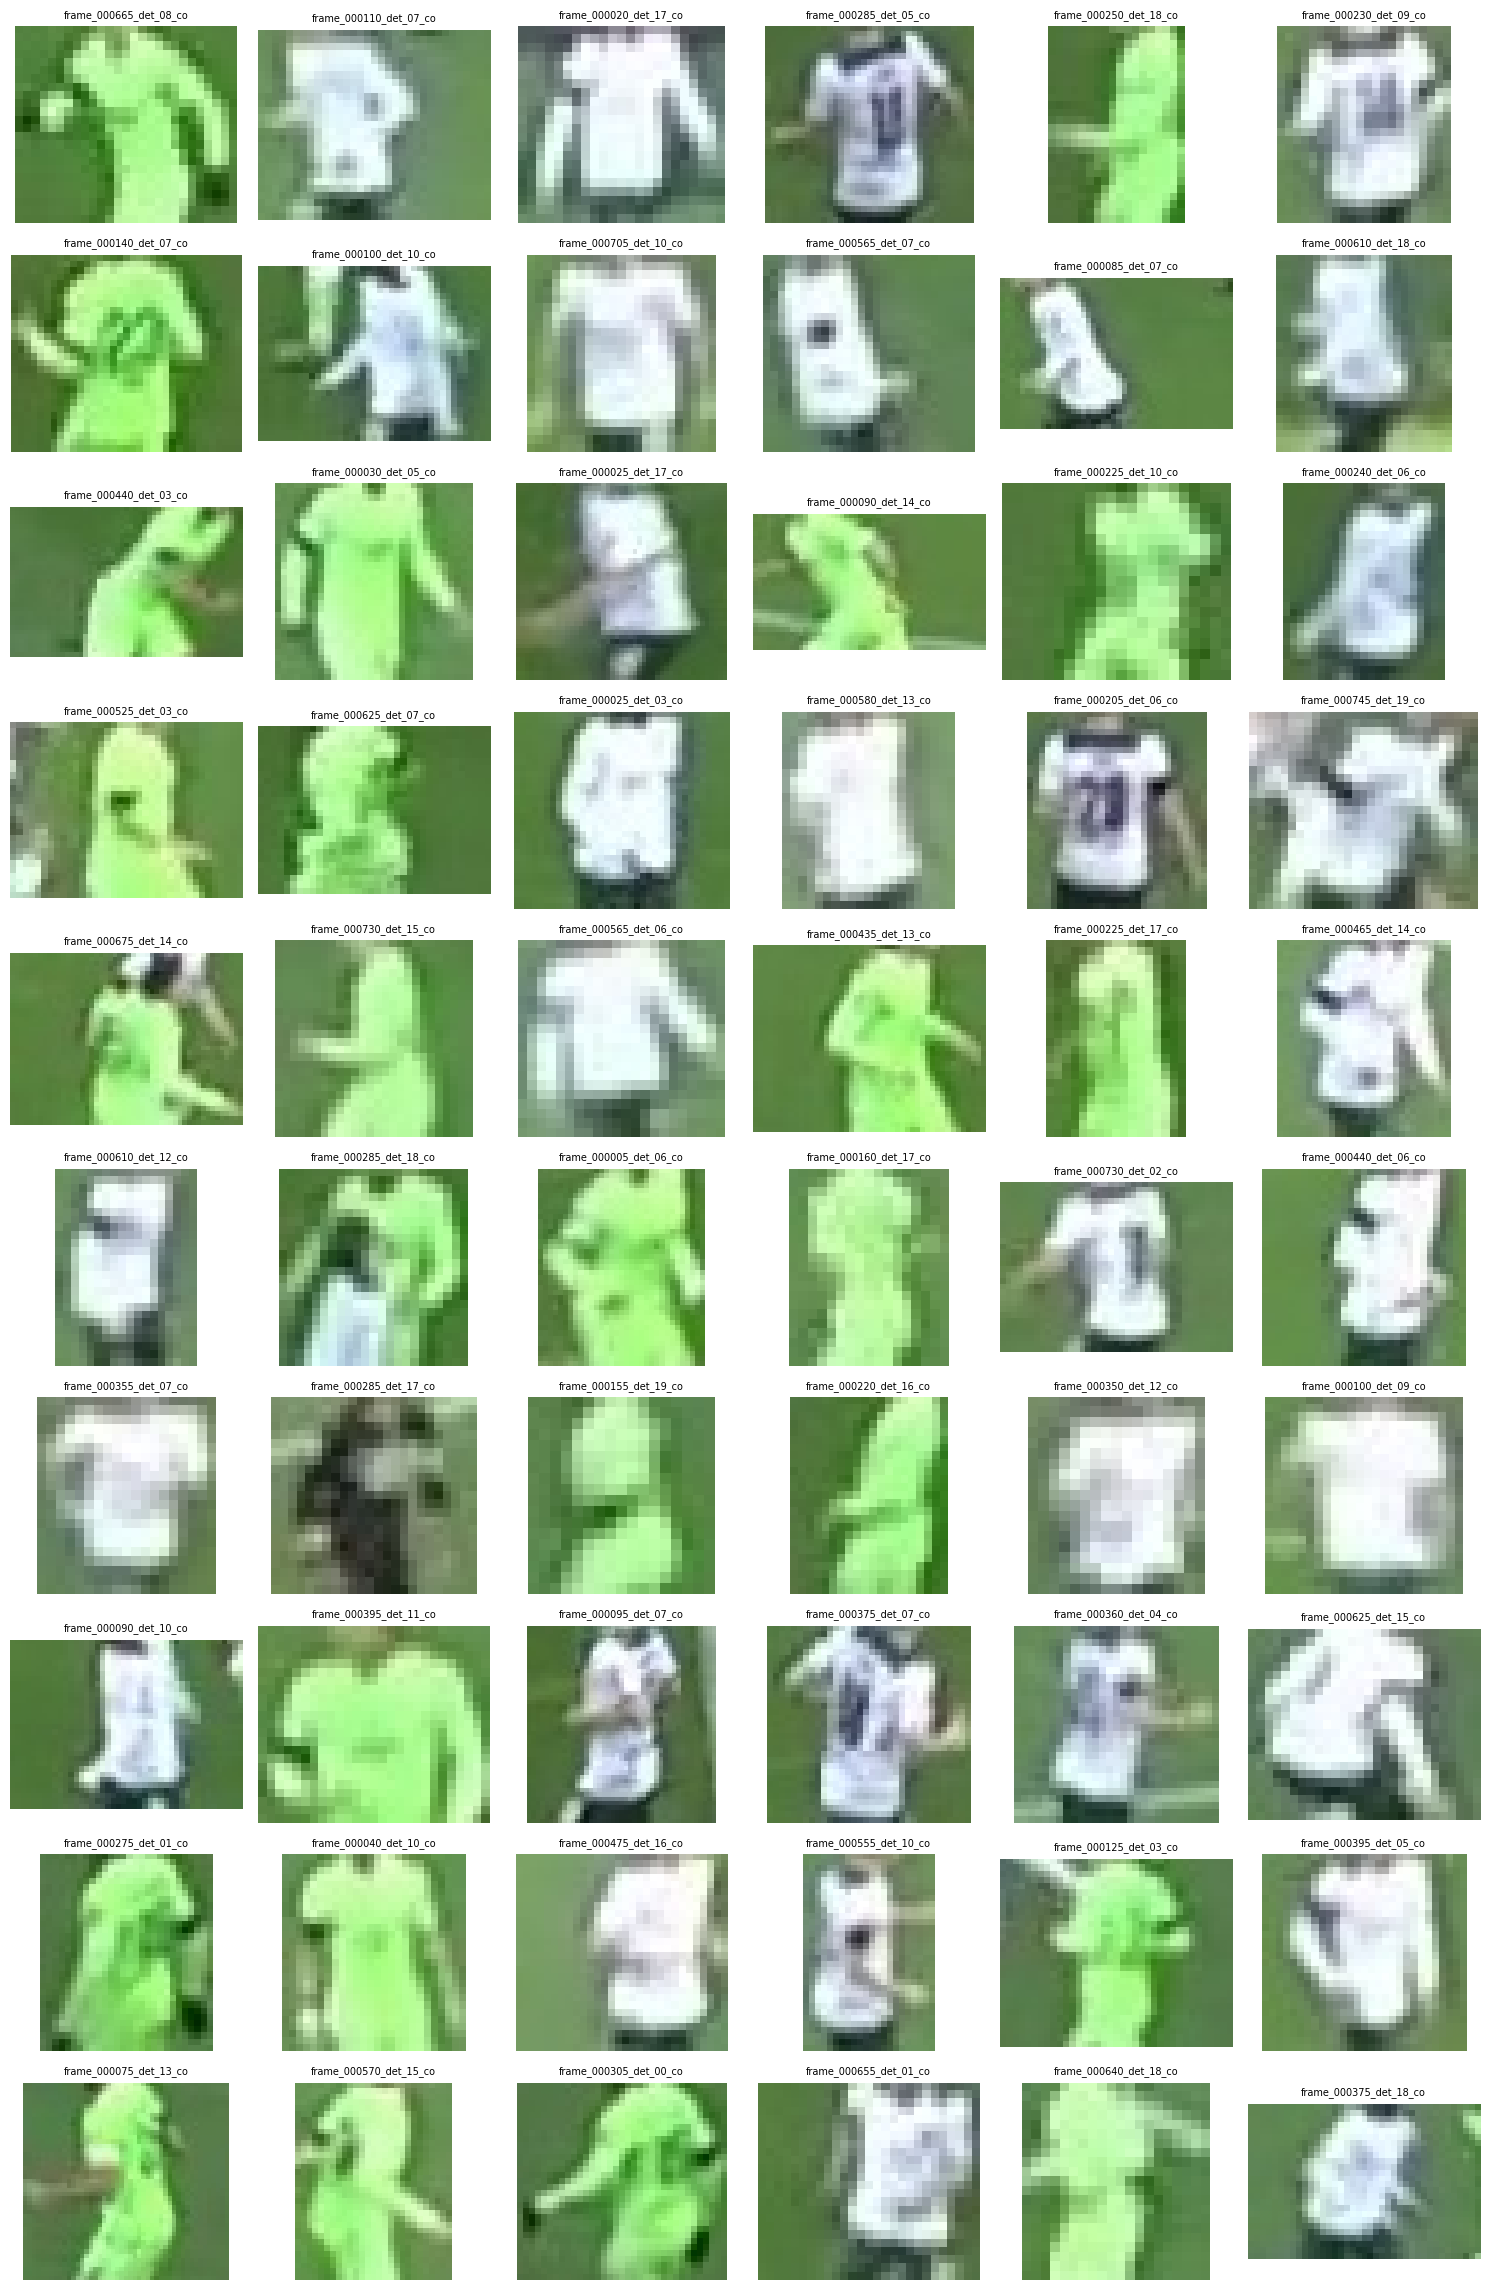

Total crops available: 2933


In [4]:

import os
import random
import math
import cv2
import matplotlib.pyplot as plt

CROPS_DIR = "/kaggle/working/FootballVision/phase3_team_id/player_crops"

crop_files = sorted([
    f for f in os.listdir(CROPS_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

if not crop_files:
    raise RuntimeError("No crops found. Check the model and video paths.")

random.seed(42)
sample_files = random.sample(
    crop_files,
    min(60, len(crop_files))
)

cols = 6
rows = math.ceil(len(sample_files) / cols)

plt.figure(figsize=(15, rows * 2.3))

for i, filename in enumerate(sample_files):
    path = os.path.join(CROPS_DIR, filename)
    image = cv2.imread(path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(rows, cols, i + 1)
    plt.imshow(image)
    plt.title(filename[:22], fontsize=7)
    plt.axis("off")

plt.tight_layout()
plt.show()

print(f"Total crops available: {len(crop_files)}")


Extracting colors:   0%|          | 0/2933 [00:00<?, ?it/s]

Valid crops: 2932
Feature matrix: (2932, 194)
Silhouette score: 0.215
(A rough clustering diagnostic, not team accuracy.)

Crops assigned:
team
Team B    1473
Team A    1459
Name: count, dtype: int64
CSV saved to: /kaggle/working/FootballVision/phase3_team_id/team_clustering/crop_team_assignments.csv


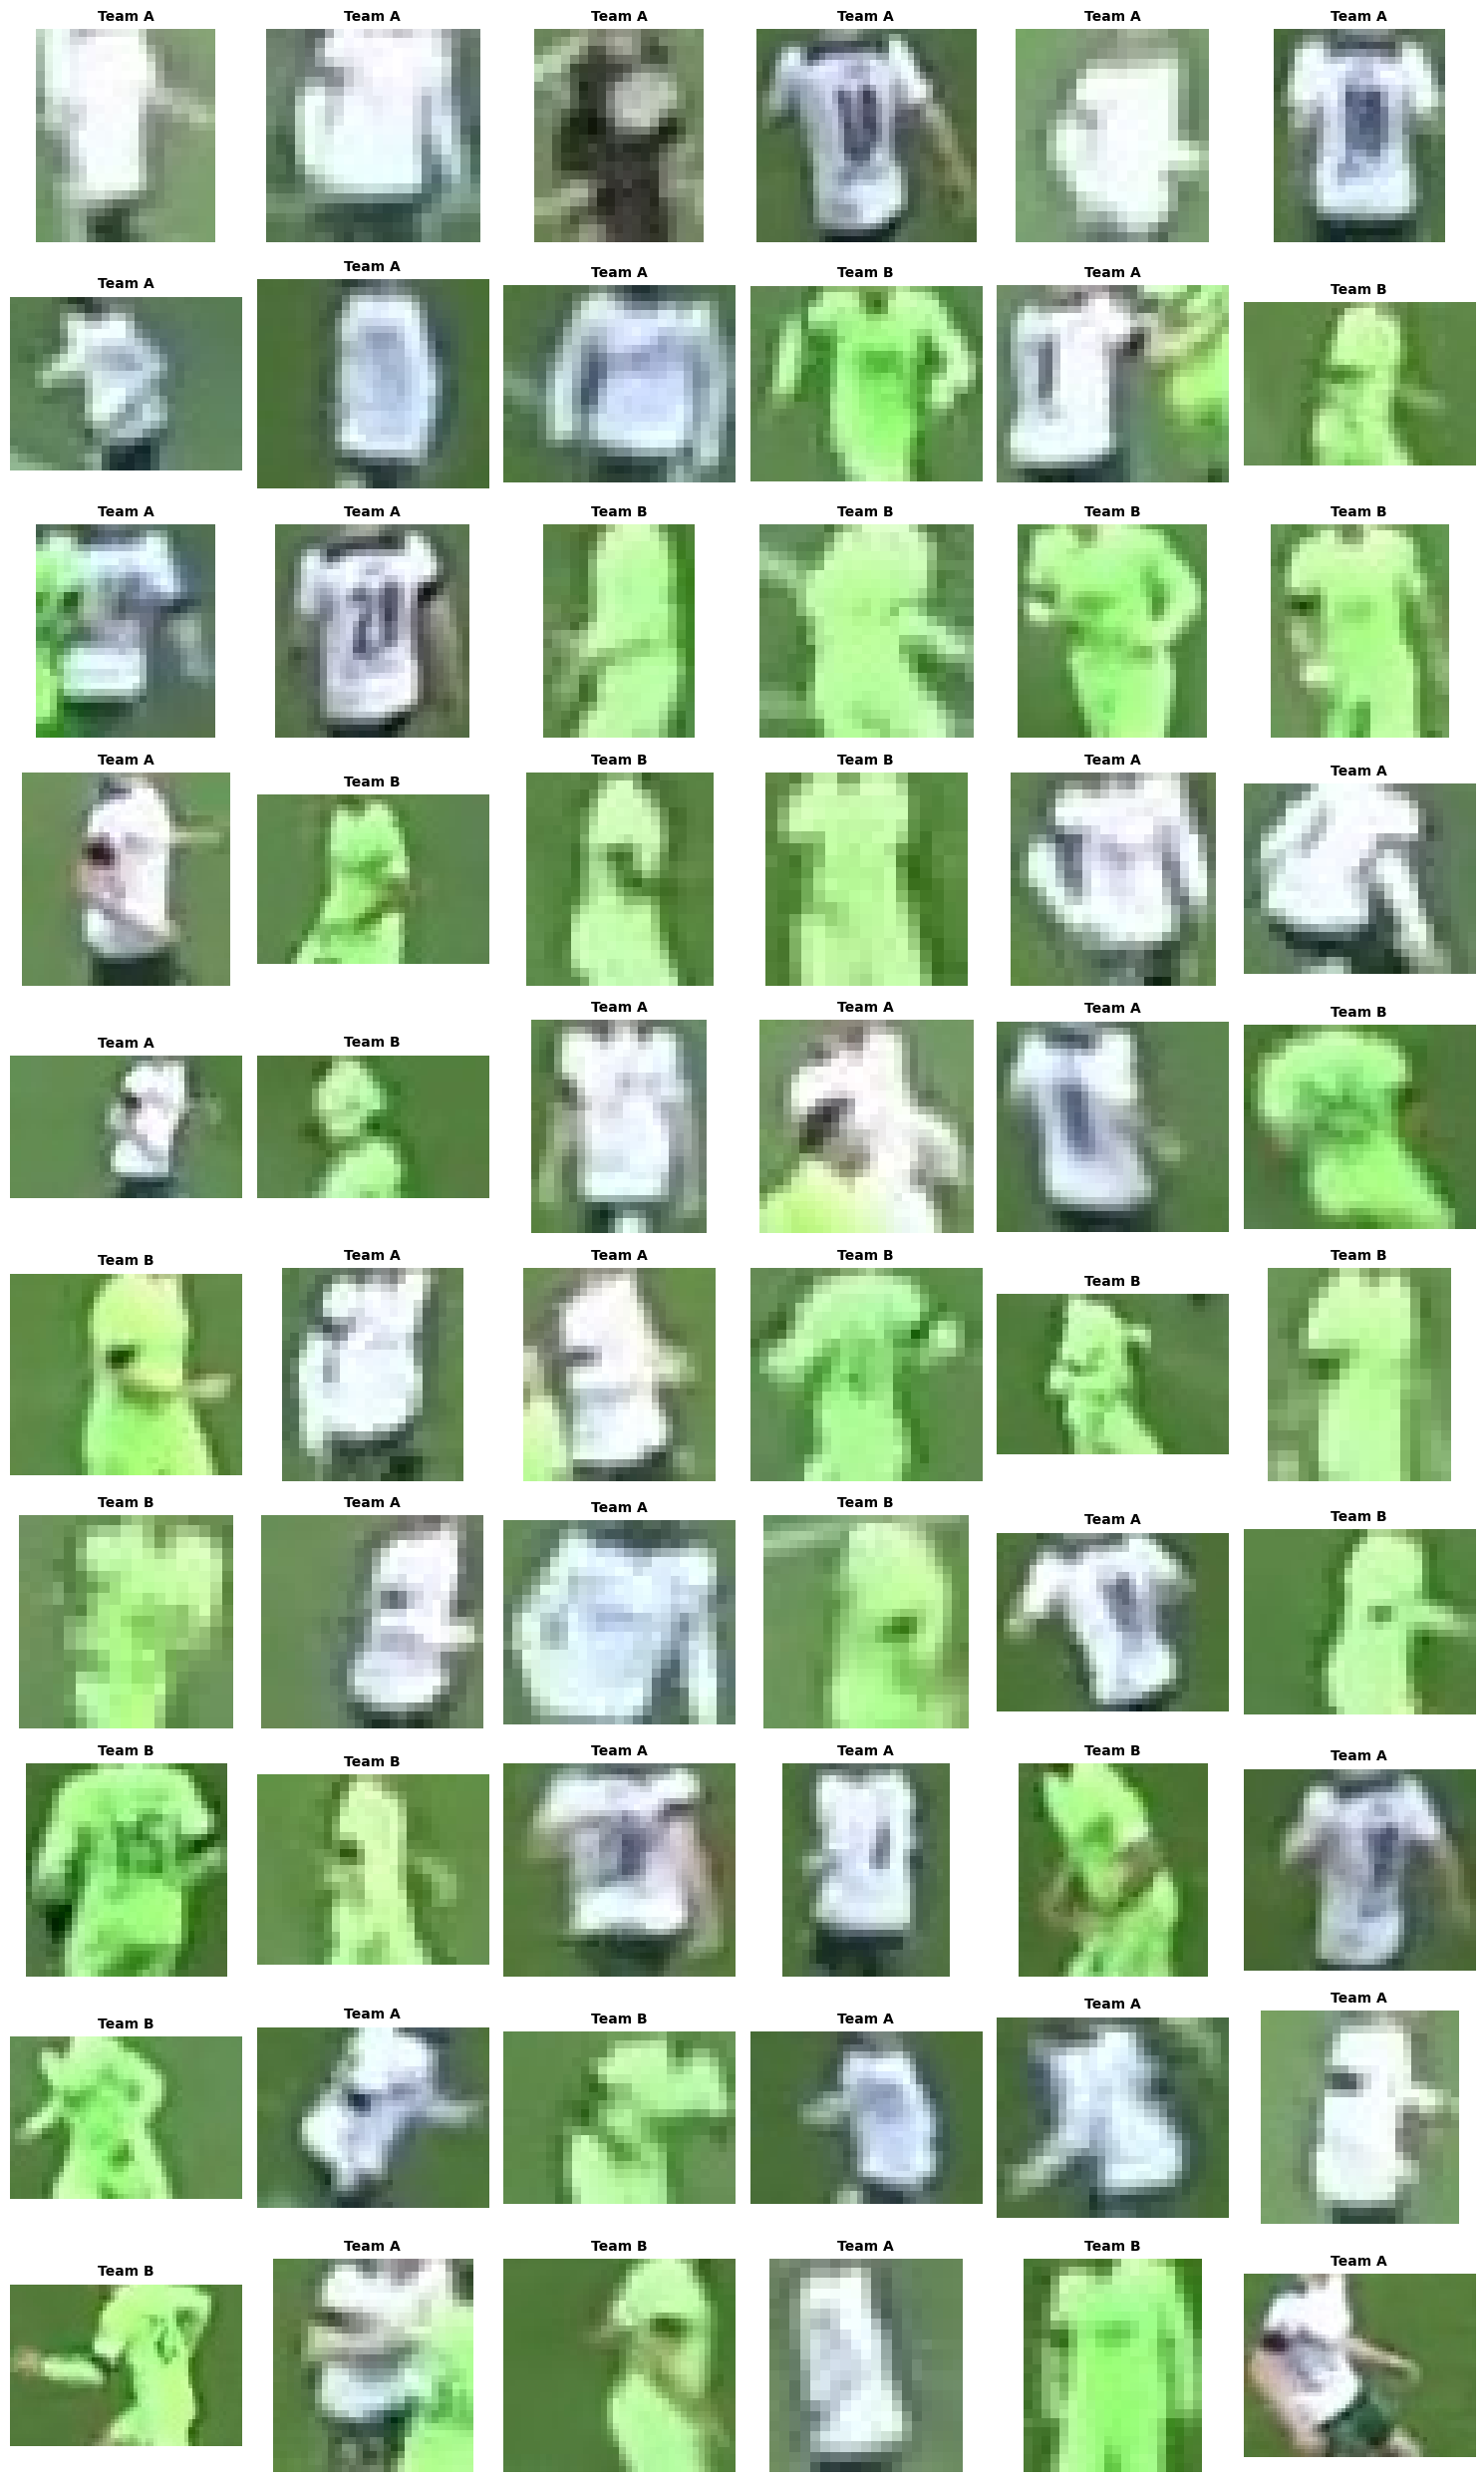

Contact sheet saved to: /kaggle/working/FootballVision/phase3_team_id/team_clustering/team_contact_sheet.png


In [5]:

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from tqdm.auto import tqdm

# ============================================================
# CONFIG
# ============================================================

BASE_DIR = Path(
    "/kaggle/working/FootballVision/phase3_team_id"
)
CROPS_DIR = BASE_DIR / "player_crops"
OUTPUT_DIR = BASE_DIR / "team_clustering"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
N_TEAMS = 2

# ============================================================
# COLOR FEATURE EXTRACTION
# ============================================================

def extract_jersey_features(image_path):
    """
    Extract dominant HSV color information from a player crop.
    Uses the central region to reduce background contamination.
    """

    image = cv2.imread(str(image_path))

    if image is None:
        return None

    h, w = image.shape[:2]

    if h < 8 or w < 8:
        return None

    # Resize to a common size for consistent feature extraction.
    image = cv2.resize(image, (64, 64))

    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Focus on the center of the crop, where the jersey
    # is more likely to be located.
    y1, y2 = int(0.10 * 64), int(0.85 * 64)
    x1, x2 = int(0.15 * 64), int(0.85 * 64)

    region = hsv[y1:y2, x1:x2]

    hue = region[:, :, 0].astype(np.float32)
    sat = region[:, :, 1].astype(np.float32)
    val = region[:, :, 2].astype(np.float32)

    # Green pitch pixels can dominate small distant crops.
    # OpenCV hue for green is approximately 30–90.
    grass_mask = (hue >= 30) & (hue <= 90) & (sat > 45)

    # Keep non-grass pixels where possible.
    # If most pixels are masked, fall back to the whole region.
    if np.mean(~grass_mask) > 0.25:
        pixels = region[~grass_mask]
    else:
        pixels = region.reshape(-1, 3)

    if len(pixels) == 0:
        pixels = region.reshape(-1, 3)

    # Color histogram captures color distribution rather than
    # relying only on one average color.
    hist = cv2.calcHist(
        [pixels.reshape(-1, 1, 3)],
        [0, 1, 2],
        None,
        [12, 4, 4],
        [0, 180, 0, 256, 0, 256]
    ).flatten()

    hist = hist / (hist.sum() + 1e-8)

    # Add average saturation and brightness.
    mean_sat = float(np.mean(pixels[:, 1])) / 255.0
    mean_val = float(np.mean(pixels[:, 2])) / 255.0

    return np.concatenate([hist, [mean_sat, mean_val]])


# ============================================================
# LOAD FEATURES
# ============================================================

if not CROPS_DIR.exists():
    raise FileNotFoundError(f"Crop folder not found: {CROPS_DIR}")

image_paths = sorted([
    p for p in CROPS_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

if len(image_paths) < N_TEAMS:
    raise RuntimeError("Not enough crops to cluster.")

features = []
valid_paths = []

for path in tqdm(image_paths, desc="Extracting colors"):
    feature = extract_jersey_features(path)

    if feature is not None:
        features.append(feature)
        valid_paths.append(path)

X = np.asarray(features, dtype=np.float32)

if len(X) < N_TEAMS:
    raise RuntimeError("Not enough valid crops.")

print("Valid crops:", len(valid_paths))
print("Feature matrix:", X.shape)

# ============================================================
# CLUSTER INTO TWO COLOR GROUPS
# ============================================================

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(
    n_clusters=N_TEAMS,
    random_state=RANDOM_STATE,
    n_init=20
)

labels = kmeans.fit_predict(X_scaled)

if len(set(labels)) > 1 and len(X_scaled) > N_TEAMS:
    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(2000, len(X_scaled)),
        random_state=RANDOM_STATE
    )
    print(f"Silhouette score: {score:.3f}")
    print("(A rough clustering diagnostic, not team accuracy.)")

# ============================================================
# SAVE RESULTS
# ============================================================

df = pd.DataFrame({
    "crop_path": [str(p) for p in valid_paths],
    "crop_filename": [p.name for p in valid_paths],
    "team_cluster": labels
})

df["team"] = df["team_cluster"].map({
    0: "Team A",
    1: "Team B"
})

csv_path = OUTPUT_DIR / "crop_team_assignments.csv"
df.to_csv(csv_path, index=False)

print("\nCrops assigned:")
print(df["team"].value_counts())
print("CSV saved to:", csv_path)

# ============================================================
# CREATE LABELED CONTACT SHEET
# ============================================================

rng = np.random.default_rng(RANDOM_STATE)

sample_indices = rng.choice(
    len(valid_paths),
    size=min(60, len(valid_paths)),
    replace=False
)

cols = 6
rows = int(np.ceil(len(sample_indices) / cols))

fig, axes = plt.subplots(
    rows, cols,
    figsize=(15, rows * 2.5)
)

axes = np.array(axes).reshape(-1)

for ax in axes:
    ax.axis("off")

for ax, idx in zip(axes, sample_indices):
    image = cv2.imread(str(valid_paths[idx]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    team = df.iloc[idx]["team"]

    ax.imshow(image)
    ax.set_title(team, fontsize=10, fontweight="bold")
    ax.axis("off")

plt.tight_layout()

sheet_path = OUTPUT_DIR / "team_contact_sheet.png"
plt.savefig(sheet_path, dpi=150, bbox_inches="tight")
plt.show()

print("Contact sheet saved to:", sheet_path)


In [7]:

import cv2
import numpy as np
from pathlib import Path
from collections import defaultdict
from ultralytics import YOLO
from sklearn.cluster import KMeans
from tqdm.auto import tqdm

# ============================================================
# CONFIGURATION
# ============================================================

MODEL_PATH = "/kaggle/input/datasets/anishnagargoje/footballviddeo/best (1).pt"
VIDEO_PATH = "/kaggle/input/datasets/anishnagargoje/footballviddeo/08fd33_4.mp4"

BASE_DIR = Path("/kaggle/working/FootballVision/phase3_team_id")
BASE_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_VIDEO = str(BASE_DIR / "football_all_classes_annotated4.mp4")

TRACKER_CONFIG = "ocsort.yaml"

IMAGE_SIZE = 960     #1280
TRACK_CONFIDENCE = 0.15

# Per-class display thresholds. These affect which detections
# are drawn, not the tracker's internal association thresholds.
PLAYER_DISPLAY_CONF = 0.15
BALL_DISPLAY_CONF = 0.02
GK_DISPLAY_CONF = 0.15
REF_DISPLAY_CONF = 0.15

MIN_COLOR_OBSERVATIONS = 5

# Model class IDs
BALL_CLASS = 0
GOALKEEPER_CLASS = 1
PLAYER_CLASS = 2
REFEREE_CLASS = 3

# OpenCV uses BGR color order.
TEAM_A_COLOR = (255, 100, 0)       # Blue
TEAM_B_COLOR = (255, 0, 200)       # Magenta
UNKNOWN_COLOR = (155, 155, 155)    # Grey
BALL_COLOR = (0, 255, 255)         # Yellow
GOALKEEPER_COLOR = (0, 165, 255)   # Orange
REFEREE_COLOR = (245, 245, 245)    # White

# Compact annotation style
BOX_THICKNESS = 2
FONT = cv2.FONT_HERSHEY_SIMPLEX
FONT_SCALE = 0.43
FONT_THICKNESS = 1
PAD_X = 5
PAD_Y = 3

# ============================================================
# JERSEY COLOR FEATURE
# Used ONLY for outfield players (class 2).
# We deliberately do not remove green pixels: green may be
# the actual jersey color of one of the teams.
# ============================================================

def get_jersey_feature(frame, xyxy):
    x1, y1, x2, y2 = map(int, xyxy)

    h, w = frame.shape[:2]
    x1, x2 = max(0, x1), min(w, x2)
    y1, y2 = max(0, y1), min(h, y2)

    bw, bh = x2 - x1, y2 - y1

    if bw < 8 or bh < 20:
        return None

    # Approximate torso region: avoid head and most of the legs.
    xa = x1 + int(0.20 * bw)
    xb = x2 - int(0.20 * bw)
    ya = y1 + int(0.18 * bh)
    yb = y1 + int(0.58 * bh)

    if xb <= xa or yb <= ya:
        return None

    crop = frame[ya:yb, xa:xb]

    if crop.size == 0:
        return None

    crop = cv2.resize(crop, (32, 32))
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)

    pixels = hsv.reshape(-1, 3).astype(np.float32)

    # Median color reduces the influence of a few noisy pixels.
    median = np.median(pixels, axis=0)

    return np.array([
        median[0] / 180.0,   # Hue
        median[1] / 255.0,   # Saturation
        median[2] / 255.0    # Brightness
    ], dtype=np.float32)


# ============================================================
# INPUT VALIDATION
# ============================================================

if not Path(MODEL_PATH).exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

if not Path(VIDEO_PATH).exists():
    raise FileNotFoundError(f"Video not found: {VIDEO_PATH}")

model = YOLO(MODEL_PATH)

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

cap.release()

if fps <= 0 or width <= 0 or height <= 0:
    raise RuntimeError("Could not read valid video properties.")

# ============================================================
# PASS 1: TRACK ALL CLASSES
# ============================================================

# Each frame stores every displayed detection, including class
# and track ID. We reuse these detections during rendering.
frame_detections = []

# Collect jersey colors only for outfield-player tracks.
track_color_observations = defaultdict(list)

class_counts = defaultdict(int)

cap = cv2.VideoCapture(VIDEO_PATH)

print("Pass 1/2: tracking ball, goalkeepers, players and referees...")

for frame_idx in tqdm(range(total_frames), desc="Tracking"):
    ret, frame = cap.read()

    if not ret:
        break

    # No classes filter: the model can track all four classes.
    result = model.track(
        source=frame,
        persist=True,
        tracker=TRACKER_CONFIG,
        imgsz=IMAGE_SIZE,
        conf=TRACK_CONFIDENCE,
        device=0,
        verbose=False
    )[0]

    current_detections = []
    boxes = result.boxes

    if boxes is not None and len(boxes) > 0:
        xyxys = boxes.xyxy.cpu().numpy()
        classes = boxes.cls.int().cpu().tolist()
        confidences = boxes.conf.cpu().numpy()

        if boxes.id is not None:
            track_ids = boxes.id.int().cpu().tolist()
        else:
            track_ids = [None] * len(xyxys)

        for track_id, xyxy, cls_id, confidence in zip(
            track_ids, xyxys, classes, confidences
        ):
            cls_id = int(cls_id)
            confidence = float(confidence)

            # Display threshold for each class.
            if cls_id == BALL_CLASS:
                display_threshold = BALL_DISPLAY_CONF
            elif cls_id == GOALKEEPER_CLASS:
                display_threshold = GK_DISPLAY_CONF
            elif cls_id == PLAYER_CLASS:
                display_threshold = PLAYER_DISPLAY_CONF
            elif cls_id == REFEREE_CLASS:
                display_threshold = REF_DISPLAY_CONF
            else:
                continue

            if confidence < display_threshold:
                continue

            track_id = (
                int(track_id) if track_id is not None else None
            )

            detection = {
                "track_id": track_id,
                "class_id": cls_id,
                "confidence": confidence,
                "xyxy": xyxy.copy()
            }

            current_detections.append(detection)
            class_counts[cls_id] += 1

            # Only outfield players participate in team clustering.
            if cls_id == PLAYER_CLASS and track_id is not None:
                feature = get_jersey_feature(frame, xyxy)

                if feature is not None:
                    track_color_observations[track_id].append(feature)

    frame_detections.append(current_detections)

cap.release()

print("\nTracking pass complete.")
print("Frames processed:", len(frame_detections))
print("Ball detections drawn:", class_counts[BALL_CLASS])
print("Goalkeeper detections drawn:", class_counts[GOALKEEPER_CLASS])
print("Outfield-player detections drawn:", class_counts[PLAYER_CLASS])
print("Referee detections drawn:", class_counts[REFEREE_CLASS])
print("Player tracks with color observations:",
      len(track_color_observations))

# ============================================================
# PASS 2: ASSIGN TEAMS TO OUTFIELD PLAYERS ONLY
# ============================================================

track_ids_for_clustering = []
track_features = []

for track_id, observations in track_color_observations.items():
    if len(observations) < MIN_COLOR_OBSERVATIONS:
        continue

    # Combine repeated observations to reduce single-frame noise.
    median_feature = np.median(
        np.stack(observations),
        axis=0
    )

    track_ids_for_clustering.append(track_id)
    track_features.append(median_feature)

track_to_team = {}

if len(track_features) >= 2:
    X = np.stack(track_features)

    # Represent hue as a circular feature.
    hue_angle = X[:, 0] * 2 * np.pi

    cluster_features = np.column_stack([
        np.cos(hue_angle),
        np.sin(hue_angle),
        X[:, 1] * 0.6,
        X[:, 2] * 0.6
    ])

    kmeans = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=20
    )

    clusters = kmeans.fit_predict(cluster_features)

    track_to_team = {
        track_id: int(cluster)
        for track_id, cluster in zip(
            track_ids_for_clustering, clusters
        )
    }

else:
    print(
        "Warning: insufficient player tracks for two-team "
        "clustering. Player annotations will use grey."
    )

print("\nTeam assignment complete.")
print("Team A tracks:", sum(v == 0 for v in track_to_team.values()))
print("Team B tracks:", sum(v == 1 for v in track_to_team.values()))
print(
    "Unassigned/short player tracks:",
    len(track_color_observations) - len(track_to_team)
)

# ============================================================
# LABEL DRAWING HELPERS
# ============================================================

def get_label_dimensions(text):
    (text_w, text_h), baseline = cv2.getTextSize(
        text, FONT, FONT_SCALE, FONT_THICKNESS
    )

    label_w = text_w + 2 * PAD_X
    label_h = text_h + 2 * PAD_Y

    return label_w, label_h, text_h, baseline


def rectangles_overlap(a, b, gap=2):
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b

    return not (
        ax2 + gap <= bx1 or
        bx2 + gap <= ax1 or
        ay2 + gap <= by1 or
        by2 + gap <= ay1
    )


def draw_compact_label(
    frame,
    text,
    box,
    color,
    text_color,
    occupied_labels
):
    """
    Prefer placing the label above its detection box.
    Try alternative positions when another label occupies
    the same area. Keep the label inside the video frame.
    """

    h, w = frame.shape[:2]
    x1, y1, x2, y2 = box

    label_w, label_h, text_h, baseline = get_label_dimensions(text)

    # Candidate positions: above, below, then inside the box.
    candidates = [
        (x1, y1 - label_h - 3),
        (x1, y2 + 3),
        (x1, y1 + 2),
        (x2 - label_w, y1 - label_h - 3),
        (x2 - label_w, y2 + 3)
    ]

    chosen = None

    for cx, cy in candidates:
        cx = int(max(0, min(cx, w - label_w)))
        cy = int(max(0, min(cy, h - label_h)))

        rect = (cx, cy, cx + label_w, cy + label_h)

        if not any(
            rectangles_overlap(rect, other, gap=2)
            for other in occupied_labels
        ):
            chosen = (cx, cy, rect)
            break

    if chosen is None:
        # If every candidate is occupied, prefer above the box.
        cx = int(max(0, min(x1, w - label_w)))
        cy = int(max(0, min(y1 - label_h - 3, h - label_h)))
        rect = (cx, cy, cx + label_w, cy + label_h)
        chosen = (cx, cy, rect)

    cx, cy, rect = chosen
    occupied_labels.append(rect)

    cv2.rectangle(
        frame,
        (cx, cy),
        (cx + label_w, cy + label_h),
        color,
        -1
    )

    cv2.putText(
        frame,
        text,
        (cx + PAD_X, cy + PAD_Y + text_h),
        FONT,
        FONT_SCALE,
        text_color,
        FONT_THICKNESS,
        cv2.LINE_AA
    )


# ============================================================
# PASS 3: RENDER THE FINAL VIDEO
# ============================================================

cap = cv2.VideoCapture(VIDEO_PATH)

writer = cv2.VideoWriter(
    OUTPUT_VIDEO,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Could not create output video.")

print("\nPass 2/2: rendering clean annotations...")

for frame_idx, detections in enumerate(
    tqdm(frame_detections, desc="Rendering")
):
    ret, frame = cap.read()

    if not ret:
        break

    render_items = []

    for det in detections:
        track_id = det["track_id"]
        cls_id = det["class_id"]
        x1, y1, x2, y2 = map(int, det["xyxy"])

        # Clamp boxes to frame boundaries.
        x1 = max(0, min(x1, width - 1))
        x2 = max(0, min(x2, width - 1))
        y1 = max(0, min(y1, height - 1))
        y2 = max(0, min(y2, height - 1))

        if cls_id == PLAYER_CLASS:
            team = track_to_team.get(track_id)

            if team == 0:
                color = TEAM_A_COLOR
            elif team == 1:
                color = TEAM_B_COLOR
            else:
                color = UNKNOWN_COLOR

            # Requested: only #ID for outfield players.
            label = f"#{track_id}" if track_id is not None else "#?"

            text_color = (255, 255, 255)

        elif cls_id == GOALKEEPER_CLASS:
            color = GOALKEEPER_COLOR
            label = (
                f"GK #{track_id}"
                if track_id is not None
                else "GK"
            )
            text_color = (20, 20, 20)

        elif cls_id == REFEREE_CLASS:
            color = REFEREE_COLOR
            label = (
                f"REF #{track_id}"
                if track_id is not None
                else "REF"
            )
            text_color = (20, 20, 20)

        elif cls_id == BALL_CLASS:
            color = BALL_COLOR
            label = (
                f"BALL #{track_id}"
                if track_id is not None
                else "BALL"
            )
            text_color = (20, 20, 20)

        else:
            continue

        render_items.append({
            "box": (x1, y1, x2, y2),
            "class_id": cls_id,
            "color": color,
            "label": label,
            "text_color": text_color
        })

    # Draw all boxes first so label placement can be handled separately.
    for item in render_items:
        x1, y1, x2, y2 = item["box"]
        cls_id = item["class_id"]
        color = item["color"]

        if cls_id == BALL_CLASS:
            # Circle is more visible for the small ball.
            cx = (x1 + x2) // 2
            cy = (y1 + y2) // 2
            radius = max(5, int(max(x2 - x1, y2 - y1) / 2))

            cv2.circle(frame, (cx, cy), radius, color, 2)
        else:
            cv2.rectangle(
                frame,
                (x1, y1),
                (x2, y2),
                color,
                BOX_THICKNESS
            )

    # Place labels in vertical order to reduce collisions.
    render_items.sort(key=lambda item: item["box"][1])

    occupied_labels = []

    for item in render_items:
        draw_compact_label(
            frame,
            item["label"],
            item["box"],
            item["color"],
            item["text_color"],
            occupied_labels
        )

    writer.write(frame)

cap.release()
writer.release()

print("\nSUCCESS!")
print("Annotated video saved to:")
print(OUTPUT_VIDEO)


Pass 1/2: tracking ball, goalkeepers, players and referees...


Tracking:   0%|          | 0/750 [00:00<?, ?it/s]


Tracking pass complete.
Frames processed: 750
Ball detections drawn: 257
Goalkeeper detections drawn: 525
Outfield-player detections drawn: 14859
Referee detections drawn: 2145
Player tracks with color observations: 32

Team assignment complete.
Team A tracks: 15
Team B tracks: 11
Unassigned/short player tracks: 6

Pass 2/2: rendering clean annotations...


Rendering:   0%|          | 0/750 [00:00<?, ?it/s]


SUCCESS!
Annotated video saved to:
/kaggle/working/FootballVision/phase3_team_id/football_all_classes_annotated4.mp4


## deepocsort

In [3]:

import cv2
import yaml
import numpy as np

from pathlib import Path
from collections import defaultdict
from ultralytics import YOLO
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

# ============================================================
# CONFIG
# ============================================================

MODEL_PATH = "/kaggle/input/datasets/anishnagargoje/footballviddeo/best (1).pt"
VIDEO_PATH = "/kaggle/input/datasets/anishnagargoje/footballviddeo/08fd33_4.mp4"

BASE_DIR = Path("/kaggle/working/FootballVision/phase3_team_id")
BASE_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_VIDEO = str(BASE_DIR / "football_teams_improved.mp4")

# Recreate the custom tracker YAML every run.
# This avoids the missing-file error after a Kaggle restart.
TRACKER_CONFIG = str(BASE_DIR / "deepocsort_reid.yaml")

# Class IDs from your trained model
BALL_CLASS = 0
GOALKEEPER_CLASS = 1
PLAYER_CLASS = 2
REFEREE_CLASS = 3

# Detection settings
PERSON_IMAGE_SIZE = 1280
BALL_IMAGE_SIZE = 1536

PERSON_MODEL_CONF = 0.10
BALL_MODEL_CONF = 0.03

PLAYER_DISPLAY_CONF = 0.15
GK_DISPLAY_CONF = 0.15
REF_DISPLAY_CONF = 0.15
BALL_DISPLAY_CONF = 0.03

MIN_COLOR_OBSERVATIONS = 5

# OpenCV colors are BGR
TEAM_A_COLOR = (255, 100, 0)       # Blue
TEAM_B_COLOR = (255, 0, 200)       # Magenta
UNKNOWN_COLOR = (155, 155, 155)    # Grey
BALL_COLOR = (0, 255, 255)         # Yellow
GK_COLOR = (0, 165, 255)           # Orange
REF_COLOR = (245, 245, 245)        # White

# Compact annotations
FONT = cv2.FONT_HERSHEY_SIMPLEX
FONT_SCALE = 0.43
FONT_THICKNESS = 1
BOX_THICKNESS = 2
PAD_X = 5
PAD_Y = 3

# ============================================================
# CREATE TRACKER CONFIG
# ============================================================

deepocsort_config = {
    "tracker_type": "deepocsort",
    "track_high_thresh": 0.18,
    "track_low_thresh": 0.05,
    "new_track_thresh": 0.18,
    "track_buffer": 60,
    "match_thresh": 0.8,
    "fuse_score": True,

    "delta_t": 3,
    "inertia": 0.2,
    "use_byte": False,

    # Appearance matching / re-identification
    "with_reid": True,
    "model": "auto",
    "proximity_thresh": 0.5,
    "appearance_thresh": 0.9,
    "alpha_fixed_emb": 0.95,

    # Helpful for a broadcast camera that pans
    "gmc_method": "sparseOptFlow",
}

with open(TRACKER_CONFIG, "w") as f:
    yaml.safe_dump(deepocsort_config, f, sort_keys=False)

print("Tracker config created:", TRACKER_CONFIG)

# ============================================================
# JERSEY COLOR FEATURE
# Only used for outfield players, not goalkeepers/referees.
# ============================================================

def get_jersey_feature(frame, xyxy):
    x1, y1, x2, y2 = map(int, xyxy)
    h, w = frame.shape[:2]

    x1 = max(0, min(x1, w - 1))
    x2 = max(0, min(x2, w))
    y1 = max(0, min(y1, h - 1))
    y2 = max(0, min(y2, h))

    bw, bh = x2 - x1, y2 - y1

    if bw < 8 or bh < 20:
        return None

    # Focus on the torso, excluding head, legs and crop edges.
    xa = x1 + int(0.20 * bw)
    xb = x2 - int(0.20 * bw)
    ya = y1 + int(0.18 * bh)
    yb = y1 + int(0.58 * bh)

    if xb <= xa or yb <= ya:
        return None

    crop = frame[ya:yb, xa:xb]

    if crop.size == 0:
        return None

    crop = cv2.resize(crop, (32, 32))
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    pixels = hsv.reshape(-1, 3).astype(np.float32)

    hue = pixels[:, 0]
    sat = pixels[:, 1]
    val = pixels[:, 2]

    # Use saturation-weighted circular hue features.
    # Low-saturation white jerseys should rely more on saturation
    # and brightness than on noisy hue values.
    weights = sat + 1.0
    angles = hue * (2.0 * np.pi / 180.0)

    hue_cos = np.average(np.cos(angles), weights=weights)
    hue_sin = np.average(np.sin(angles), weights=weights)

    median_sat = np.median(sat) / 255.0
    upper_sat = np.percentile(sat, 75) / 255.0
    median_val = np.median(val) / 255.0

    return np.array([
        median_sat,
        upper_sat,
        median_val,
        hue_cos * median_sat,
        hue_sin * median_sat
    ], dtype=np.float32)


# ============================================================
# VALIDATE INPUT AND OPEN VIDEO
# ============================================================

if not Path(MODEL_PATH).exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

if not Path(VIDEO_PATH).exists():
    raise FileNotFoundError(f"Video not found: {VIDEO_PATH}")

# Separate model instances keep ball predictions independent
# from the persistent person-tracking state.
person_model = YOLO(MODEL_PATH)
ball_model = YOLO(MODEL_PATH)

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError(f"Cannot open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

cap.release()

if fps <= 0 or width <= 0 or height <= 0:
    raise RuntimeError("Invalid video properties.")

# ============================================================
# PASS 1: TRACK PEOPLE + DETECT BALL
# ============================================================

frame_detections = []
track_color_observations = defaultdict(list)

print("Pass 1: tracking people and detecting the ball...")

cap = cv2.VideoCapture(VIDEO_PATH)

for frame_idx in tqdm(range(total_frames), desc="Analyzing video"):
    ret, frame = cap.read()

    if not ret:
        break

    current = []

    # --------------------------------------------------------
    # A. Track goalkeepers, outfield players and referees.
    # Ball detection is deliberately handled independently.
    # --------------------------------------------------------

    person_result = person_model.track(
        source=frame,
        persist=True,
        tracker=TRACKER_CONFIG,
        imgsz=PERSON_IMAGE_SIZE,
        conf=PERSON_MODEL_CONF,
        classes=[GOALKEEPER_CLASS, PLAYER_CLASS, REFEREE_CLASS],
        device=0,
        verbose=False
    )[0]

    boxes = person_result.boxes

    if boxes is not None and len(boxes) > 0:
        xyxys = boxes.xyxy.cpu().numpy()
        classes = boxes.cls.int().cpu().tolist()
        confidences = boxes.conf.cpu().numpy()

        if boxes.id is not None:
            track_ids = boxes.id.int().cpu().tolist()
        else:
            track_ids = [None] * len(xyxys)

        for track_id, xyxy, cls_id, confidence in zip(
            track_ids, xyxys, classes, confidences
        ):
            cls_id = int(cls_id)
            confidence = float(confidence)
            track_id = int(track_id) if track_id is not None else None

            display_threshold = {
                PLAYER_CLASS: PLAYER_DISPLAY_CONF,
                GOALKEEPER_CLASS: GK_DISPLAY_CONF,
                REFEREE_CLASS: REF_DISPLAY_CONF
            }.get(cls_id, 1.0)

            # Retain boxes suitable for the final visualization.
            if confidence < display_threshold:
                continue

            current.append({
                "track_id": track_id,
                "class_id": cls_id,
                "confidence": confidence,
                "xyxy": xyxy.copy()
            })

            # Only the outfield players contribute to team clusters.
            if cls_id == PLAYER_CLASS and track_id is not None:
                feature = get_jersey_feature(frame, xyxy)

                if feature is not None:
                    track_color_observations[track_id].append(feature)

    # --------------------------------------------------------
    # B. Detect the ball separately at a larger image size
    # and lower confidence threshold.
    # We select the strongest ball candidate in each frame.
    # --------------------------------------------------------

    ball_result = ball_model.predict(
        source=frame,
        imgsz=BALL_IMAGE_SIZE,
        conf=BALL_MODEL_CONF,
        classes=[BALL_CLASS],
        device=0,
        verbose=False
    )[0]

    ball_boxes = ball_result.boxes

    if ball_boxes is not None and len(ball_boxes) > 0:
        ball_confs = ball_boxes.conf.cpu().numpy()
        best_idx = int(np.argmax(ball_confs))
        best_conf = float(ball_confs[best_idx])

        if best_conf >= BALL_DISPLAY_CONF:
            ball_xyxy = ball_boxes.xyxy[best_idx].cpu().numpy()

            current.append({
                "track_id": None,
                "class_id": BALL_CLASS,
                "confidence": best_conf,
                "xyxy": ball_xyxy.copy()
            })

    frame_detections.append(current)

cap.release()

print("\nFrames analyzed:", len(frame_detections))
print("Player tracks with color observations:",
      len(track_color_observations))

# ============================================================
# ASSIGN TWO TEAMS USING TRACK-LEVEL COLOR FEATURES
# ============================================================

track_ids = []
track_features = []

for track_id, observations in track_color_observations.items():
    if len(observations) < MIN_COLOR_OBSERVATIONS:
        continue

    # One robust color profile from repeated observations.
    track_feature = np.median(
        np.stack(observations),
        axis=0
    )

    track_ids.append(track_id)
    track_features.append(track_feature)

track_to_team = {}

if len(track_features) >= 2:
    X = np.stack(track_features)

    # Scale features so no single channel dominates clustering.
    X_scaled = StandardScaler().fit_transform(X)

    kmeans = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_scaled)

    track_to_team = {
        track_id: int(label)
        for track_id, label in zip(track_ids, labels)
    }
else:
    print(
        "Warning: insufficient repeated player observations "
        "to form two teams. Unassigned players will be grey."
    )

print("Team A tracks:", sum(v == 0 for v in track_to_team.values()))
print("Team B tracks:", sum(v == 1 for v in track_to_team.values()))

# ============================================================
# COMPACT LABEL DRAWING
# ============================================================

def label_dimensions(text):
    (tw, th), baseline = cv2.getTextSize(
        text, FONT, FONT_SCALE, FONT_THICKNESS
    )
    return tw + 2 * PAD_X, th + 2 * PAD_Y, th


def overlap(a, b, gap=2):
    return not (
        a[2] + gap <= b[0] or
        b[2] + gap <= a[0] or
        a[3] + gap <= b[1] or
        b[3] + gap <= a[1]
    )


def draw_label(frame, text, box, bg_color, text_color, occupied):
    h, w = frame.shape[:2]
    x1, y1, x2, y2 = box

    label_w, label_h, text_h = label_dimensions(text)

    candidates = [
        (x1, y1 - label_h - 3),  # above
        (x1, y2 + 3),            # below
        (x1, y1 + 2),            # inside top
        (x2 - label_w, y1 - label_h - 3),
        (x2 - label_w, y2 + 3)
    ]

    chosen = None

    for x, y in candidates:
        x = int(max(0, min(x, w - label_w)))
        y = int(max(0, min(y, h - label_h)))

        rect = (x, y, x + label_w, y + label_h)

        if not any(overlap(rect, other) for other in occupied):
            chosen = (x, y, rect)
            break

    if chosen is None:
        x = int(max(0, min(x1, w - label_w)))
        y = int(max(0, min(y1 - label_h - 3, h - label_h)))
        chosen = (x, y, (x, y, x + label_w, y + label_h))

    x, y, rect = chosen
    occupied.append(rect)

    cv2.rectangle(
        frame,
        (x, y),
        (x + label_w, y + label_h),
        bg_color,
        -1
    )

    cv2.putText(
        frame,
        text,
        (x + PAD_X, y + PAD_Y + text_h),
        FONT,
        FONT_SCALE,
        text_color,
        FONT_THICKNESS,
        cv2.LINE_AA
    )


# ============================================================
# PASS 2: RENDER ANNOTATED VIDEO
# ============================================================

cap = cv2.VideoCapture(VIDEO_PATH)

writer = cv2.VideoWriter(
    OUTPUT_VIDEO,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Could not create output video.")

print("Pass 2: rendering annotations...")

for detections in tqdm(frame_detections, desc="Rendering"):
    ret, frame = cap.read()

    if not ret:
        break

    render_items = []

    for det in detections:
        track_id = det["track_id"]
        cls_id = det["class_id"]

        x1, y1, x2, y2 = map(int, det["xyxy"])

        x1 = max(0, min(x1, width - 1))
        x2 = max(0, min(x2, width - 1))
        y1 = max(0, min(y1, height - 1))
        y2 = max(0, min(y2, height - 1))

        if cls_id == PLAYER_CLASS:
            team = track_to_team.get(track_id)

            if team == 0:
                color = TEAM_A_COLOR
            elif team == 1:
                color = TEAM_B_COLOR
            else:
                color = UNKNOWN_COLOR

            text = f"#{track_id}" if track_id is not None else "#?"

        elif cls_id == GOALKEEPER_CLASS:
            color = GK_COLOR
            text = f"GK #{track_id}" if track_id is not None else "GK"

        elif cls_id == REFEREE_CLASS:
            color = REF_COLOR
            text = f"REF #{track_id}" if track_id is not None else "REF"

        elif cls_id == BALL_CLASS:
            color = BALL_COLOR
            text = "BALL"

        else:
            continue

        render_items.append({
            "box": (x1, y1, x2, y2),
            "class_id": cls_id,
            "color": color,
            "text": text
        })

    # Draw boxes/circle first.
    for item in render_items:
        x1, y1, x2, y2 = item["box"]
        cls_id = item["class_id"]
        color = item["color"]

        if cls_id == BALL_CLASS:
            cx = (x1 + x2) // 2
            cy = (y1 + y2) // 2
            radius = max(5, int(max(x2 - x1, y2 - y1) / 2))
            cv2.circle(frame, (cx, cy), radius, color, 2)
        else:
            cv2.rectangle(
                frame, (x1, y1), (x2, y2), color, BOX_THICKNESS
            )

    # Place higher boxes first to reduce overlapping labels.
    render_items.sort(key=lambda item: item["box"][1])
    occupied = []

    for item in render_items:
        if item["class_id"] in (BALL_CLASS, REFEREE_CLASS):
            text_color = (20, 20, 20)
        else:
            text_color = (255, 255, 255)

        draw_label(
            frame,
            item["text"],
            item["box"],
            item["color"],
            text_color,
            occupied
        )

    writer.write(frame)

cap.release()
writer.release()

print("\nCOMPLETE")
print("Output video:", OUTPUT_VIDEO)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Tracker config created: /kaggle/working/FootballVision/phase3_team_id/deepocsort_reid.yaml
Pass 1: tracking people and detecting the ball...


Analyzing video:   0%|          | 0/750 [00:00<?, ?it/s]

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 250ms
Prepared 1 package in 43ms
Installed 1 package in 2ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


Frames analyzed: 750
Player tracks with color observations: 54
Team A tracks: 17
Team B tracks: 17
Pass 2: rendering annotations...


Rendering:   0%|          | 0/750 [00:00<?, ?it/s]


COMPLETE
Output video: /kaggle/working/FootballVision/phase3_team_id/football_teams_improved.mp4


## final code for phase 2 

In [10]:

import cv2
import pickle
import numpy as np

from pathlib import Path
from collections import defaultdict
from ultralytics import YOLO
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

# ============================================================
# CONFIGURATION
# ============================================================

MODEL_PATH = "/kaggle/input/datasets/anishnagargoje/footballviddeo/best (1).pt"
VIDEO_PATH = "/kaggle/input/datasets/anishnagargoje/footballviddeo/08fd33_4.mp4"

BASE_DIR = Path("/kaggle/working/FootballVision/phase3_team_id")
BASE_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_PATH = BASE_DIR / "tracking_results1.pkl"

# Change this line to test another installed tracker.
# Available in your environment: ocsort.yaml, deepocsort.yaml,
# botsort.yaml, bytetrack.yaml, fasttrack.yaml, tracktrack.yaml
TRACKER_CONFIG = "ocsort.yaml"

# Model class IDs
BALL_CLASS = 0
GOALKEEPER_CLASS = 1
PLAYER_CLASS = 2
REFEREE_CLASS = 3

# Tracking / inference settings
PERSON_IMAGE_SIZE = 960
PERSON_CONFIDENCE = 0.10

BALL_IMAGE_SIZE = 1536
BALL_CONFIDENCE = 0.03

# Minimum confidence for keeping a detection in saved results.
PLAYER_DISPLAY_CONF = 0.15
GK_DISPLAY_CONF = 0.15
REF_DISPLAY_CONF = 0.15
BALL_DISPLAY_CONF = 0.03

MIN_COLOR_OBSERVATIONS = 5

# ============================================================
# JERSEY COLOR FEATURE
# Used ONLY for outfield players, class 2.
# ============================================================

def get_jersey_feature(frame, xyxy):
    x1, y1, x2, y2 = map(int, xyxy)
    h, w = frame.shape[:2]

    x1 = max(0, min(x1, w - 1))
    x2 = max(0, min(x2, w))
    y1 = max(0, min(y1, h - 1))
    y2 = max(0, min(y2, h))

    bw, bh = x2 - x1, y2 - y1

    if bw < 8 or bh < 20:
        return None

    # Upper torso region: exclude most of the head and legs.
    xa = x1 + int(0.20 * bw)
    xb = x2 - int(0.20 * bw)
    ya = y1 + int(0.18 * bh)
    yb = y1 + int(0.58 * bh)

    if xb <= xa or yb <= ya:
        return None

    crop = frame[ya:yb, xa:xb]

    if crop.size == 0:
        return None

    crop = cv2.resize(crop, (32, 32))
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    pixels = hsv.reshape(-1, 3).astype(np.float32)

    hue = pixels[:, 0]
    saturation = pixels[:, 1]
    brightness = pixels[:, 2]

    # Circular representation for hue, weighted by saturation.
    # This makes hue less influential for white/grey jerseys.
    weights = saturation + 1.0
    angles = hue * (2.0 * np.pi / 180.0)

    hue_cos = np.average(np.cos(angles), weights=weights)
    hue_sin = np.average(np.sin(angles), weights=weights)

    med_sat = np.median(saturation) / 255.0
    upper_sat = np.percentile(saturation, 75) / 255.0
    med_brightness = np.median(brightness) / 255.0

    return np.array([
        med_sat,
        upper_sat,
        med_brightness,
        hue_cos * med_sat,
        hue_sin * med_sat
    ], dtype=np.float32)


# ============================================================
# VALIDATE INPUTS
# ============================================================

if not Path(MODEL_PATH).exists():
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

if not Path(VIDEO_PATH).exists():
    raise FileNotFoundError(f"Video not found: {VIDEO_PATH}")

# Separate model/tracker instances prevent one person class
# from inheriting another class's tracking state.
print("Loading models...")

person_models = {
    class_id: YOLO(MODEL_PATH)
    for class_id in [PLAYER_CLASS, GOALKEEPER_CLASS, REFEREE_CLASS]
}

ball_model = YOLO(MODEL_PATH)

# ============================================================
# VIDEO METADATA
# ============================================================

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

cap.release()

if fps <= 0 or width <= 0 or height <= 0:
    raise RuntimeError("Invalid video properties.")

# ============================================================
# PASS 1: TRACK PEOPLE, DETECT BALL, COLLECT JERSEY COLORS
# ============================================================

frame_detections = []
track_color_observations = defaultdict(list)
tracks_seen = defaultdict(set)

cap = cv2.VideoCapture(VIDEO_PATH)

print(f"Tracker: {TRACKER_CONFIG}")
print("Tracking each person class separately...")
print("Detecting ball independently at high resolution...")

for frame_idx in tqdm(range(total_frames), desc="Tracking"):
    ret, frame = cap.read()

    if not ret:
        break

    current = []

    # --------------------------------------------------------
    # TRACK PLAYERS, GOALKEEPERS AND REFEREES
    # Each class has its own persistent tracker state.
    # --------------------------------------------------------

    for class_id in [PLAYER_CLASS, GOALKEEPER_CLASS, REFEREE_CLASS]:
        result = person_models[class_id].track(
            source=frame,
            persist=True,
            tracker=TRACKER_CONFIG,
            imgsz=PERSON_IMAGE_SIZE,
            conf=PERSON_CONFIDENCE,
            classes=[class_id],
            device=0,
            verbose=False
        )[0]

        boxes = result.boxes

        if boxes is None or len(boxes) == 0:
            continue

        xyxys = boxes.xyxy.cpu().numpy()
        confidences = boxes.conf.cpu().numpy()

        if boxes.id is not None:
            ids = boxes.id.int().cpu().tolist()
        else:
            ids = [None] * len(xyxys)

        display_threshold = {
            PLAYER_CLASS: PLAYER_DISPLAY_CONF,
            GOALKEEPER_CLASS: GK_DISPLAY_CONF,
            REFEREE_CLASS: REF_DISPLAY_CONF
        }[class_id]

        for track_id, xyxy, confidence in zip(
            ids, xyxys, confidences
        ):
            confidence = float(confidence)
            track_id = int(track_id) if track_id is not None else None

            # Only save detections above the chosen display threshold.
            if confidence < display_threshold:
                continue

            current.append({
                "track_id": track_id,
                "class_id": class_id,
                "confidence": confidence,
                "xyxy": xyxy.astype(float).tolist()
            })

            if track_id is not None:
                tracks_seen[class_id].add(track_id)

            # Collect jersey-color observations ONLY for outfield
            # players. Goalkeepers and referees never enter clustering.
            if class_id == PLAYER_CLASS and track_id is not None:
                feature = get_jersey_feature(frame, xyxy)

                if feature is not None:
                    track_color_observations[track_id].append(feature)

    # --------------------------------------------------------
    # DETECT BALL INDEPENDENTLY
    # Ball inference is not tied to the person tracker.
    # Keep the strongest ball candidate in each frame.
    # --------------------------------------------------------

    ball_result = ball_model.predict(
        source=frame,
        imgsz=BALL_IMAGE_SIZE,
        conf=BALL_CONFIDENCE,
        classes=[BALL_CLASS],
        device=0,
        verbose=False
    )[0]

    ball_boxes = ball_result.boxes

    if ball_boxes is not None and len(ball_boxes) > 0:
        ball_confidences = ball_boxes.conf.cpu().numpy()
        best_idx = int(np.argmax(ball_confidences))
        best_conf = float(ball_confidences[best_idx])

        if best_conf >= BALL_DISPLAY_CONF:
            ball_xyxy = ball_boxes.xyxy[best_idx].cpu().numpy()

            # The ball is detected separately, not given a persistent
            # tracking ID in this version.
            current.append({
                "track_id": None,
                "class_id": BALL_CLASS,
                "confidence": best_conf,
                "xyxy": ball_xyxy.astype(float).tolist()
            })

    frame_detections.append(current)

cap.release()

print("\nTracking finished.")
print("Frames analyzed:", len(frame_detections))

for class_id, name in [
    (PLAYER_CLASS, "Outfield-player"),
    (GOALKEEPER_CLASS, "Goalkeeper"),
    (REFEREE_CLASS, "Referee")
]:
    print(f"{name} tracks:", len(tracks_seen[class_id]))

# ============================================================
# PASS 2: CLUSTER OUTFIELD PLAYER TRACKS INTO TWO TEAMS
# ============================================================

all_track_features = {}
stable_track_ids = []

for track_id, observations in track_color_observations.items():
    if len(observations) == 0:
        continue

    all_track_features[track_id] = np.median(
        np.stack(observations), axis=0
    )

    if len(observations) >= MIN_COLOR_OBSERVATIONS:
        stable_track_ids.append(track_id)

track_to_team = {}

# Prefer tracks with repeated color observations to fit clusters.
# If there aren't enough, fall back to available player tracks.
if len(stable_track_ids) >= 2:
    fit_track_ids = stable_track_ids
else:
    fit_track_ids = list(all_track_features.keys())

if len(fit_track_ids) >= 2:
    X_fit = np.stack([
        all_track_features[tid] for tid in fit_track_ids
    ])

    scaler = StandardScaler()
    X_fit_scaled = scaler.fit_transform(X_fit)

    kmeans = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=20
    )

    kmeans.fit(X_fit_scaled)

    # Classify shorter tracks against the learned team profiles too.
    all_ids = list(all_track_features.keys())
    X_all = np.stack([all_track_features[tid] for tid in all_ids])
    X_all_scaled = scaler.transform(X_all)
    all_labels = kmeans.predict(X_all_scaled)

    track_to_team = {
        tid: int(label)
        for tid, label in zip(all_ids, all_labels)
    }

print("Player tracks with jersey features:", len(all_track_features))
print("Team A tracks:", sum(v == 0 for v in track_to_team.values()))
print("Team B tracks:", sum(v == 1 for v in track_to_team.values()))

# ============================================================
# SAVE RESULTS FOR THE ANNOTATION CELL
# ============================================================

results_bundle = {
    "metadata": {
        "video_path": VIDEO_PATH,
        "fps": fps,
        "width": width,
        "height": height,
        "frames": len(frame_detections),
        "tracker_config": TRACKER_CONFIG
    },
    "frame_detections": frame_detections,
    "track_to_team": track_to_team
}

with open(RESULTS_PATH, "wb") as f:
    pickle.dump(results_bundle, f, protocol=pickle.HIGHEST_PROTOCOL)

print("\nTRACKING RESULTS SAVED")
print("File:", RESULTS_PATH)
print("You can now run the annotation cell independently.")


Loading models...
Tracker: ocsort.yaml
Tracking each person class separately...
Detecting ball independently at high resolution...


Tracking:   0%|          | 0/750 [00:00<?, ?it/s]


Tracking finished.
Frames analyzed: 750
Outfield-player tracks: 29
Goalkeeper tracks: 4
Referee tracks: 5
Player tracks with jersey features: 29
Team A tracks: 14
Team B tracks: 15

TRACKING RESULTS SAVED
File: /kaggle/working/FootballVision/phase3_team_id/tracking_results1.pkl
You can now run the annotation cell independently.


In [11]:

import cv2
import pickle
from pathlib import Path
from tqdm.auto import tqdm

# ============================================================
# ANNOTATION SETTINGS
# Edit this section freely without rerunning tracking.
# ============================================================

BASE_DIR = Path("/kaggle/working/FootballVision/phase3_team_id")
RESULTS_PATH = BASE_DIR / "tracking_results1.pkl"

OUTPUT_VIDEO = str(BASE_DIR / "football_teams_annotated2.mp4")

# OpenCV colors are BGR.
TEAM_A_COLOR = (255, 100, 0)       # Blue
TEAM_B_COLOR = (255, 0, 200)       # Magenta
UNKNOWN_COLOR = (155, 155, 155)    # Grey
BALL_COLOR = (0, 255, 255)         # Yellow
GK_COLOR = (0, 165, 255)           # Orange
REF_COLOR = (245, 245, 245)        # White

BOX_THICKNESS = 2
FONT = cv2.FONT_HERSHEY_SIMPLEX
FONT_SCALE = 0.43
FONT_THICKNESS = 1
PAD_X = 5
PAD_Y = 3

# ============================================================
# LOAD TRACKING RESULTS
# ============================================================

if not RESULTS_PATH.exists():
    raise FileNotFoundError(
        f"Tracking results not found: {RESULTS_PATH}. "
        "Run Cell 1 first."
    )

with open(RESULTS_PATH, "rb") as f:
    bundle = pickle.load(f)

metadata = bundle["metadata"]
frame_detections = bundle["frame_detections"]
track_to_team = bundle["track_to_team"]

VIDEO_PATH = metadata["video_path"]
fps = metadata["fps"]
width = metadata["width"]
height = metadata["height"]

# ============================================================
# DRAWING HELPERS
# ============================================================

def label_dimensions(text):
    (tw, th), _ = cv2.getTextSize(
        text, FONT, FONT_SCALE, FONT_THICKNESS
    )

    return (
        tw + 2 * PAD_X,
        th + 2 * PAD_Y,
        th
    )


def overlaps(a, b, gap=2):
    return not (
        a[2] + gap <= b[0] or
        b[2] + gap <= a[0] or
        a[3] + gap <= b[1] or
        b[3] + gap <= a[1]
    )


def draw_label(frame, text, box, color, text_color, occupied):
    """Draw a compact label inside the frame, avoiding prior labels."""

    h, w = frame.shape[:2]
    x1, y1, x2, y2 = box

    label_w, label_h, text_h = label_dimensions(text)

    candidates = [
        (x1, y1 - label_h - 3),  # Above the box
        (x1, y2 + 3),            # Below the box
        (x1, y1 + 2),            # Inside the box
        (x2 - label_w, y1 - label_h - 3),
        (x2 - label_w, y2 + 3)
    ]

    chosen = None

    for x, y in candidates:
        x = max(0, min(int(x), max(0, w - label_w)))
        y = max(0, min(int(y), max(0, h - label_h)))

        rect = (x, y, x + label_w, y + label_h)

        if not any(overlaps(rect, other) for other in occupied):
            chosen = (x, y, rect)
            break

    if chosen is None:
        x = max(0, min(x1, max(0, w - label_w)))
        y = max(0, min(y1 - label_h - 3, max(0, h - label_h)))
        chosen = (x, y, (x, y, x + label_w, y + label_h))

    x, y, rect = chosen
    occupied.append(rect)

    cv2.rectangle(
        frame,
        (x, y),
        (x + label_w, y + label_h),
        color,
        -1
    )

    cv2.putText(
        frame,
        text,
        (x + PAD_X, y + PAD_Y + text_h),
        FONT,
        FONT_SCALE,
        text_color,
        FONT_THICKNESS,
        cv2.LINE_AA
    )


# ============================================================
# RENDER VIDEO
# ============================================================

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError(f"Could not reopen input video: {VIDEO_PATH}")

writer = cv2.VideoWriter(
    OUTPUT_VIDEO,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Could not create output video.")

print("Rendering saved tracking results...")
print("Tracker used:", metadata["tracker_config"])

for detections in tqdm(frame_detections, desc="Rendering"):
    ret, frame = cap.read()

    if not ret:
        break

    render_items = []

    for det in detections:
        track_id = det["track_id"]
        class_id = det["class_id"]

        x1, y1, x2, y2 = map(int, det["xyxy"])

        # Clamp detection coordinates to the video boundaries.
        x1 = max(0, min(x1, width - 1))
        x2 = max(0, min(x2, width - 1))
        y1 = max(0, min(y1, height - 1))
        y2 = max(0, min(y2, height - 1))

        if class_id == 2:  # Outfield player
            team = track_to_team.get(track_id)

            if team == 0:
                color = TEAM_A_COLOR
            elif team == 1:
                color = TEAM_B_COLOR
            else:
                color = UNKNOWN_COLOR

            # Requested format: #1, #2, etc.
            text = f"#{track_id}" if track_id is not None else "#?"

        elif class_id == 1:  # Goalkeeper
            color = GK_COLOR
            text = f"GK #{track_id}" if track_id is not None else "GK"

        elif class_id == 3:  # Referee
            color = REF_COLOR
            text = f"REF #{track_id}" if track_id is not None else "REF"

        elif class_id == 0:  # Ball
            color = BALL_COLOR
            text = "BALL"

        else:
            continue

        render_items.append({
            "box": (x1, y1, x2, y2),
            "class_id": class_id,
            "color": color,
            "text": text
        })

    # Draw all detection boxes before placing labels.
    for item in render_items:
        x1, y1, x2, y2 = item["box"]
        class_id = item["class_id"]
        color = item["color"]

        if class_id == 0:
            cx = (x1 + x2) // 2
            cy = (y1 + y2) // 2
            radius = max(5, int(max(x2 - x1, y2 - y1) / 2))

            cv2.circle(frame, (cx, cy), radius, color, 2)
        else:
            cv2.rectangle(
                frame,
                (x1, y1),
                (x2, y2),
                color,
                BOX_THICKNESS
            )

    # Put labels on different candidate positions to minimize overlap.
    render_items.sort(key=lambda item: item["box"][1])
    occupied_labels = []

    for item in render_items:
        if item["class_id"] in (0, 3):
            text_color = (20, 20, 20)
        else:
            text_color = (255, 255, 255)

        draw_label(
            frame,
            item["text"],
            item["box"],
            item["color"],
            text_color,
            occupied_labels
        )

    writer.write(frame)

cap.release()
writer.release()

print("\nANNOTATION COMPLETE")
print("Output video:", OUTPUT_VIDEO)


Rendering saved tracking results...
Tracker used: ocsort.yaml


Rendering:   0%|          | 0/750 [00:00<?, ?it/s]


ANNOTATION COMPLETE
Output video: /kaggle/working/FootballVision/phase3_team_id/football_teams_annotated2.mp4
